## Feature-based models (`models.ipynb`)

**Question**: how well do 130 handcrafted NLP features (n-gram entropy, char distributions, length, symbol/letter ratios, TF-IDF-style stats) separate legit domains from 50 DGA families, especially under family-aware OOD shift?

This notebook is the **source of truth** for the artifact pipeline: it builds the dataset, splits, CV folds, scaler, trains all baseline models, and writes `model_artifact.json`. Downstream notebooks (`e2e_models`, `models_optimization`) load from `models/` and assert on these artifacts.

**Covered models** (6 total):
- linear: `CustomLogReg`, `SkLogReg`
- tree: `RandomForest`, `LightGBM`, `XGBoost`
- neural: `MLP`
- `production_candidates = ["LightGBM", "XGBoost", "MLP"]`; others are explored for reference

**Splits**: 10 of 50 DGA families held out for `test_ood` (family-aware OOD shift). `test_id` and `test_ood` share the same `legit_test` so FPR / FP-per-million are directly comparable. CV: 5-fold GroupKFold, `legit` split into 10 pseudo-groups via domain hash.

**Pre-registered decisions** (fixed before results):
- threshold policy: max TPR subject to FPR ≤ 1e-3 on val
- calibration: Isotonic on val (`{name}_cal.pkl`)
- primary metric: **OOD TPR@fpr=1e-3** (operational); AP secondary
- `HOLDOUT_FAMILY_FRAC=0.20`, `MIN_FAMILY_SIZE_FOR_OOD=5000`, `N_CV_SPLITS=5`

**Artifacts**:
- `dataset_processed.csv`, `split_indices.npz`, `cv_fold_indices.npz`, `scaler.pkl`
- `models/{name}.pkl`, `models/{name}_cal.pkl`
- `model_artifact.json` — features, thresholds, 17-col metrics (id/ood), latency, versions, `production_candidates`
- CV cache: `models/cv_feature/{name}/fold{k}.json` + `summary.csv`

### Section 0. Setup

- Imports, seeds, paths, cache flags (`TRAIN_CACHE`, `CV_FOLD_RESUME`, `CV_USE_SUMMARY_CACHE`, `CACHE_RESET`)
- Pre-registered: `TARGET_FPR_VAL=1e-3`, `HOLDOUT_FAMILY_FRAC=0.20`, `N_CV_SPLITS=5`, `MIN_FAMILY_SIZE_FOR_OOD=5000`
- Latency protocol: warm-up 20, repeats 200 — same as `e2e_models` / `models_optimization`
- `SKIP_PREPROCESSING` is set from `dataset_processed.csv` existence

In [1]:
import gc
import io
import json
import logging
import os
import sys
import time
import warnings
from copy import deepcopy
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost as xgb
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
SEED = 42
np.random.seed(SEED)

BASE_DIR = Path.cwd()
PATHS = {
    "legit": BASE_DIR / "legit_features.csv",
    "dga_dir": BASE_DIR / "Results",
    "dga_pattern": "*.csv",
    "legacy_full": BASE_DIR / "dataset_full.csv",
    "raw": BASE_DIR / "dataset_raw.csv",
    "raw_clean": BASE_DIR / "dataset_raw_clean.csv",
    "baseline_stats": BASE_DIR / "baseline_stats.json",
    "processed": BASE_DIR / "dataset_processed.csv",
    "splits": BASE_DIR / "split_indices.npz",
    "cv_folds": BASE_DIR / "cv_fold_indices.npz",
    "scaler": BASE_DIR / "scaler.pkl",
    "artifact": BASE_DIR / "model_artifact.json",
    "plots_dir": BASE_DIR / "plots",
    "models_dir": BASE_DIR / "models",
    "cv_feature_dir": BASE_DIR / "models" / "cv_feature",
}

Path(PATHS["plots_dir"]).mkdir(exist_ok=True)
Path(PATHS["models_dir"]).mkdir(exist_ok=True)
Path(PATHS["cv_feature_dir"]).mkdir(parents=True, exist_ok=True)

TARGET_FPR_VAL = 1e-3
REPORT_FPRS = [1e-2, 1e-3, 1e-4]
TARGET_RECALLS = [0.95, 0.99]
REALISTIC_PREVALENCES = [1e-3, 1e-4]

HOLDOUT_FAMILY_FRAC = 0.20
SHAP_SAMPLE_N = 2000
PERMUTATION_SAMPLE_N = 20000
LATENCY_SAMPLES = 1000
LATENCY_WARMUP = 20
LATENCY_REPEATS = 200

MIN_FAMILY_SIZE_FOR_OOD = 5000

N_LEGIT_GROUPS = 10
N_CV_SPLITS = 5

# Cache control (set CACHE_RESET=True to force retrain everything)
TRAIN_CACHE = True
CV_FOLD_RESUME = True
CV_USE_SUMMARY_CACHE = True
CACHE_RESET = False

assert Path(PATHS["legit"]).is_file(), f"Missing file: {PATHS['legit']}"
assert Path(PATHS["dga_dir"]).is_dir(), f"Not a directory: {PATHS['dga_dir']}"
print("BASE_DIR:", BASE_DIR)

BASE_DIR: d:\Data\Scripts


In [3]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("lightgbm").setLevel(logging.ERROR)
sns.set_style("whitegrid")

### Section 1. Data loading & preprocessing

Runs only if `dataset_processed.csv` is absent; otherwise this section is a no-op.

- Load `legit_features.csv` + 50 DGA CSVs (`Results/features_*.csv`) → `dataset_raw.csv`
- Drop 18 domains with conflicting labels (legit + DGA, 36 rows)
- Feature-vector duplicates: cross-class → drop; same-class → dedupe
- NaN → per-pattern indicator (`isnan_*`); sentinel fill: `-1` for non-negative, `0` otherwise
- Final: `dataset_processed.csv` — 132 columns (130 features + 2 NaN indicators) + label

In [4]:
SKIP_PREPROCESSING = Path(PATHS["processed"]).exists()

if SKIP_PREPROCESSING:
    full_df = pd.read_csv(PATHS["processed"])
    feature_cols = [c for c in full_df.columns if c.startswith("nlp_")]
    isnan_cols = sorted([c for c in full_df.columns if c.startswith("isnan_")])
    PRETRAINED_FEAT = feature_cols + isnan_cols
    X_all = full_df[PRETRAINED_FEAT].astype("float32")
    y_all = full_df["label"]
    groups_all = full_df["class"].values
    print(f"Loaded: {PATHS['processed']}")
    print(
        f"- shape={full_df.shape} | features={len(feature_cols)}+{len(isnan_cols)}={len(PRETRAINED_FEAT)}"
    )
    print(f"- labels={y_all.value_counts().to_dict()}")
else:
    print(f"{PATHS['processed']} not found")

Loaded: d:\Data\Scripts\dataset_processed.csv
- shape=(1999920, 135) | features=130+2=132
- labels={1: 999982, 0: 999938}


In [5]:
if Path(PATHS["legacy_full"]).exists():
    print(f"WARNING: {PATHS['legacy_full']} exists and is ignored.")

In [6]:
if not SKIP_PREPROCESSING:
    # Legit: allow 'class' but validate it
    legit = pd.read_csv(PATHS["legit"])

    if "class" in legit.columns:
        vals = legit["class"]
        non_null = vals.dropna()
        uniq = non_null.unique()
        print("legit_features.csv already has 'class' column:")
        print(
            f"  n_rows={len(legit)} | non-null={len(non_null)} | unique values={list(uniq)[:5]}"
        )
        bad = [v for v in uniq if v != "legit"]
        assert not bad, (
            f"legit_features.csv contains non-'legit' class values: {bad}. "
            "This file may be mixed with DGA data. Fix before continuing."
        )

    # Normalize: overwrite / create with the literal 'legit'
    legit["class"] = "legit"
    print(f"legit: {len(legit)} rows, class='legit' enforced\n")

    # DGA files
    dga_files = sorted(Path(PATHS["dga_dir"]).glob(PATHS["dga_pattern"]))
    assert dga_files, f"No DGA files found in {PATHS['dga_dir']}/{PATHS['dga_pattern']}"

    print(f"DGA files: {len(dga_files)}")
    for f in dga_files:
        print(f"  {f.name:45s} | {os.path.getsize(f) / 1e6:7.2f} MB")

    # Schema consistency
    # legit: domain + nlp_* (class = 'legit' set above)
    # features_<family>.csv: domain + nlp_* + class (class = family label)
    base_cols = set(legit.columns) - {"class"}
    required = base_cols

    schema_issues = []
    family_summary = []
    for f in dga_files:
        head = pd.read_csv(f)
        cols = set(head.columns)
        missing = required - cols
        extra = cols - required - {"class"}
        if missing or extra:
            schema_issues.append((f.name, "columns", sorted(missing), sorted(extra)))
            continue
        if "class" not in cols:
            schema_issues.append((f.name, "class", [], ["missing class column"]))
            continue
        uniq = head["class"].dropna().unique()
        if len(uniq) != 1:
            schema_issues.append(
                (
                    f.name,
                    "class",
                    [],
                    [f"expected 1 unique class, got {len(uniq)}: {list(uniq)[:5]}"],
                )
            )
            continue
        fam = uniq[0]
        if fam == "legit":
            schema_issues.append((f.name, "class", [], ["class=legit in a DGA file"]))
            continue
        family_summary.append((f.name, str(fam), len(head)))

    if schema_issues:
        print("\nSchema issues:")
        for name, kind, missing, extra in schema_issues:
            print(f"  {name} [{kind}]: missing={missing}, extra={extra}")
        raise ValueError("Sources have incompatible schemas or invalid class columns.")

    print(
        f"\nSchema OK: {len(dga_files)} DGA files, all contain "
        f"{len(required)} base columns + exactly one class value"
    )
    for name, fam, n in family_summary[:5]:
        print(f"  {name:45s} class={fam!r:25s} n={n}")
    if len(family_summary) > 5:
        print(f"  ... ({len(family_summary)} files total)")

    dga = pd.concat([pd.read_csv(f) for f in dga_files], ignore_index=True)
    assert "class" in dga.columns
    assert dga["class"].isna().sum() == 0, "NaN in class column after concat"

    full_df = pd.concat([legit, dga], ignore_index=True)
    full_df = full_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

    assert full_df["class"].isna().sum() == 0
    assert (full_df["class"] == "legit").sum() == len(legit), (
        f"expected {len(legit)} legit rows, got {(full_df['class'] == 'legit').sum()}. "
        "Some DGA file likely contains class='legit'."
    )

    full_df.to_csv(PATHS["raw"], index=False)

    print(f"\nfull_df shape: {full_df.shape}")
    print(f"classes: {full_df['class'].nunique()} (incl. legit)")
    print(f"\nSaved {PATHS['raw']}")

In [7]:
if not SKIP_PREPROCESSING:
    feature_cols = [c for c in full_df.columns if c.startswith("nlp_")]
    print("n_features:", len(feature_cols))

    dup_domain = full_df["domain"].duplicated().sum()
    print("duplicate domains:", dup_domain)

    conflicts = full_df.groupby("domain")["class"].nunique()
    print("domains with label conflicts:", (conflicts > 1).sum())

    dup_rows = full_df.duplicated(subset=feature_cols).sum()
    print("duplicate feature rows:", dup_rows)

    print("\nClass distribution:")
    print(full_df["class"].value_counts().to_string())

In [8]:
if not SKIP_PREPROCESSING:
    nan_mask = full_df[feature_cols].isna()

    total_nan = int(nan_mask.values.sum())
    n_features_with_nan = int(nan_mask.any().sum())
    nan_cols = [c for c in feature_cols if nan_mask[c].any()]  # ← добавлено

    print(f"total NaN cells: {total_nan}")
    print(f"features with NaN: {n_features_with_nan} / {len(feature_cols)}")

    assert total_nan > 0, (
        "No NaN in full_df. NaN indicators (isnan_*) will NOT be created."
    )

    # Per-class NaN rate
    nan_rate_legit = nan_mask[full_df["class"] == "legit"].mean()
    nan_rate_dga = nan_mask[full_df["class"] != "legit"].mean()

    nan_summary = pd.DataFrame(
        {
            "nan_legit": nan_rate_legit,
            "nan_dga": nan_rate_dga,
            "diff": (nan_rate_legit - nan_rate_dga).abs(),
        }
    ).sort_values("diff", ascending=False)

    print("\nTop-20 features by |nan_legit - nan_dga|:")
    print(nan_summary.head(20).round(4).to_string())

    # Check: NaN rate should correlate negatively with domain length
    domain_len = full_df["domain"].str.len()
    nan_per_row = nan_mask.sum(axis=1)
    corr = domain_len.corr(nan_per_row)
    print(f"\ncorr(domain_len, n_nan_per_row) = {corr:.4f}  (expect negative)")
    assert corr < 0, (
        "NaN should be more frequent in short domains. "
        "If not, NaN probably come from missing source columns, not from short lengths."
    )

    # Check: identical NaN patterns - redundant indicators
    sig_to_cols = {}
    for c in nan_cols:
        sig = nan_mask[c].values.tobytes()
        sig_to_cols.setdefault(sig, []).append(c)

    print(f"\nUnique NaN signatures: {len(sig_to_cols)} among {len(nan_cols)} features")
    for group in sig_to_cols.values():
        if len(group) > 1:
            print(f"  identical NaN: {group}")

    if "nlp_3g_tske" in nan_cols and "nlp_3g_tkur" in nan_cols:
        agree = (nan_mask["nlp_3g_tske"] == nan_mask["nlp_3g_tkur"]).mean()
        print(f"\ntske/tkur NaN agreement: {agree * 100:.4f}%")

In [9]:
if not SKIP_PREPROCESSING:
    for pair in [("nlp_2g_tske", "nlp_2g_tkur"), ("nlp_3g_tske", "nlp_3g_tkur")]:
        a, b = pair
        if a in full_df.columns and b in full_df.columns:
            rho, _ = spearmanr(full_df[a], full_df[b], nan_policy="omit")
            print(f"{a} vs {b}: spearman rho = {rho:.4f}")

In [10]:
if not SKIP_PREPROCESSING:
    # Diagnose duplicate domains BEFORE fixing anything
    domain_meta = full_df.groupby("domain").agg(
        n_rows=("class", "size"),
        classes=("class", lambda s: tuple(sorted(set(s)))),
    )
    dups = domain_meta[domain_meta["n_rows"] > 1].sort_values("n_rows", ascending=False)

    print(f"domains with >1 row: {len(dups)}")
    print(f"total rows involved: {int(dups['n_rows'].sum())}")

    def categorize(classes):
        if "legit" in classes and len(classes) > 1:
            return "legit+DGA"
        if len(classes) > 1:
            return "DGA+DGA (multi-family)"
        return "DGA+DGA (same family)"

    dups = dups.assign(kind=dups["classes"].apply(categorize))
    print("\nConflict kinds:")
    print(dups["kind"].value_counts().to_string())

    print("\nFull list:")
    print(dups[["n_rows", "classes", "kind"]].to_string())

In [11]:
if not SKIP_PREPROCESSING:
    for fam in ["gozi-nasa", "pizd"]:
        sub = full_df[full_df["class"] == fam]
        print(f"\n=== {fam} ({len(sub)} rows) ===")
        print(sub["domain"].sample(20, random_state=42).tolist())
        print(f"mean len: {sub['domain'].str.len().mean():.1f}")
        print(
            f"mean digit ratio: {sub['domain'].str.count(r'[0-9]').sum() / sub['domain'].str.len().sum():.3f}"
        )

In [12]:
if not SKIP_PREPROCESSING:
    # Remove ambiguous domains
    # Policy: if a domain has conflicting classes, drop ALL its rows.
    # Rationale: no model can learn a label for such a domain, and if it lands
    # in different splits it creates real leakage. 18 rows out of 2M is negligible.
    n_before = len(full_df)
    ambiguous_domains = set(dups.index)

    if ambiguous_domains:
        dropped = full_df[full_df["domain"].isin(ambiguous_domains)]
        print(f"Dropping {len(dropped)} rows across {len(ambiguous_domains)} domains\n")
        print(dropped[["domain", "class"]].to_string(index=False))
        full_df = full_df[~full_df["domain"].isin(ambiguous_domains)].reset_index(
            drop=True
        )

    print(
        f"\nbefore: {n_before} | after: {len(full_df)} | removed: {n_before - len(full_df)}"
    )

    assert full_df["domain"].duplicated().sum() == 0, "still have duplicate domains"
    assert (full_df.groupby("domain")["class"].nunique() > 1).sum() == 0, (
        "still have conflicts"
    )
    print("No duplicate domains, no label conflicts")

In [13]:
if not SKIP_PREPROCESSING:
    # Re-check feature duplicates AFTER domain fix
    # Same feature vector with different classes = irreducible ambiguity (worse than domain dups).
    # Same feature vector with same class = harmless noise, can be deduplicated.
    dup_mask = full_df.duplicated(subset=feature_cols, keep=False)
    dups_feat = full_df[dup_mask].copy()

    print(f"Rows with duplicate feature vectors: {len(dups_feat)}")
    print(
        f"Unique feature vectors repeating: {dups_feat.drop_duplicates(subset=feature_cols).shape[0]}"
    )

    conflict_sigs = pd.Index([])
    if len(dups_feat):
        sig_to_classes = dups_feat.groupby(feature_cols)["class"].agg(
            lambda s: tuple(sorted(set(s)))
        )
        conflict_sigs = sig_to_classes[sig_to_classes.apply(len) > 1].index

        if len(conflict_sigs):
            print(
                f"\n {len(conflict_sigs)} feature vectors appear with DIFFERENT classes:"
            )
            for i, sig in enumerate(conflict_sigs[:10]):
                mask = pd.MultiIndex.from_frame(full_df[feature_cols]).isin([sig])
                samples = full_df.loc[mask, ["domain", "class"]].head(5)
                print(f"\nsig {i}:")
                print(samples.to_string(index=False))
        else:
            print("\nAll feature duplicates are within the same class — safe to dedupe")

In [14]:
if not SKIP_PREPROCESSING:
    n_before = len(full_df)

    # Drop rows whose feature vector appears with DIFFERENT classes (irreducible).
    if len(conflict_sigs):
        mi = pd.MultiIndex.from_frame(full_df[feature_cols])
        drop_mask = mi.isin(conflict_sigs)
        print(f"Dropping {drop_mask.sum()} rows with cross-class feature collisions")
        full_df = full_df[~drop_mask].reset_index(drop=True)
    else:
        print("No cross-class feature collisions to drop")

    # Dedupe remaining exact duplicates (same class, identical features).
    # Keep first; this removes near-identical examples that add no information.
    full_df = full_df.drop_duplicates(subset=feature_cols, keep="first").reset_index(
        drop=True
    )

    print(
        f"\nBefore: {n_before} | after: {len(full_df)} | removed: {n_before - len(full_df)}"
    )

    assert full_df["domain"].duplicated().sum() == 0
    assert full_df.duplicated(subset=feature_cols).sum() == 0
    assert full_df["label"].isna().sum() == 0 if "label" in full_df.columns else True
    print("Clean: no duplicate domains, no duplicate feature vectors")

In [15]:
if not SKIP_PREPROCESSING:
    # Persist cleaned data + baseline diagnostics
    nan_mask_clean = full_df[feature_cols].isna()
    fam_sizes = full_df.loc[full_df["class"] != "legit", "class"].value_counts()

    baseline_stats = {
        "n_rows": len(full_df),
        "n_legit": int((full_df["class"] == "legit").sum()),
        "n_dga": int((full_df["class"] != "legit").sum()),
        "n_families": int(fam_sizes.shape[0]),
        "family_sizes": fam_sizes.to_dict(),
        "family_size_min": int(fam_sizes.min()),
        "family_size_max": int(fam_sizes.max()),
        "family_size_median": float(fam_sizes.median()),
        "n_nan_cells": int(nan_mask_clean.values.sum()),
        "n_features_with_nan": int(nan_mask_clean.any().sum()),
        "n_dup_domains_removed": len(ambiguous_domains),
        "n_feature_collisions_removed": int(
            len(conflict_sigs) if "conflict_sigs" in dir() else 0
        ),
        "removed_rows_total": int(2000000 - len(full_df)),
    }
    with open(PATHS["baseline_stats"], "w", encoding="utf-8") as f:
        json.dump(baseline_stats, f, ensure_ascii=False, indent=2, default=float)

    full_df.to_csv(PATHS["raw_clean"], index=False)

    print("baseline_stats saved ->", PATHS["baseline_stats"])
    print("cleaned data saved ->", PATHS["raw_clean"])
    print(
        f"\nfinal: {len(full_df)} rows | {fam_sizes.shape[0]} DGA families | "
        f"{baseline_stats['n_features_with_nan']} features with NaN"
    )

In [16]:
if not SKIP_PREPROCESSING:
    nan_mask = full_df[feature_cols].isna()
    nan_cols = [c for c in feature_cols if nan_mask[c].any()]
    assert len(nan_cols) > 0, "No NaN columns to build indicators for. See cell 1.3."

    # Group features by identical NaN signature: only one indicator per group
    sig_to_cols = {}
    for c in nan_cols:
        sig = nan_mask[c].values.tobytes()
        sig_to_cols.setdefault(sig, []).append(c)

    # One representative per unique NaN pattern
    nan_cols_representatives = [cols[0] for cols in sig_to_cols.values()]
    duplicates_skipped = [c for c in nan_cols if c not in nan_cols_representatives]

    print(
        f"NaN features: {len(nan_cols)} | unique patterns: {len(nan_cols_representatives)}"
    )
    if duplicates_skipped:
        print(f"  skipping duplicate indicators: {duplicates_skipped}")
        for cols in sig_to_cols.values():
            if len(cols) > 1:
                print(f'  - group kept="{cols[0]}"  mirrored_by={cols[1:]}')

    isnan_to_add = [
        c for c in nan_cols_representatives if f"isnan_{c}" not in full_df.columns
    ]
    print(f"new indicators to add: {len(isnan_to_add)}")
    for c in isnan_to_add:
        full_df[f"isnan_{c}"] = nan_mask[c].astype(np.int8)

    # Sentinel fill
    # -1 for non-negative features (entropy, lengths, ratios, counts):
    #   -1 is out of domain, distinguishable by trees.
    #   0 for features with negative valid values (skewness, etc.).
    sentinel_minus1, sentinel_zero = [], []
    for c in nan_cols:
        if full_df[c].min(skipna=True) >= 0:
            full_df[c] = full_df[c].fillna(-1)
            sentinel_minus1.append(c)
        else:
            full_df[c] = full_df[c].fillna(0)
            sentinel_zero.append(c)

    print(f"sentinel=-1 for {len(sentinel_minus1)} features")
    print(f"sentinel= 0 for {len(sentinel_zero)} features")

    assert full_df[feature_cols].isna().sum().sum() == 0, "NaN still present after fill"
    print("NaN after fill:", int(full_df[feature_cols].isna().sum().sum()))

In [17]:
if not SKIP_PREPROCESSING:
    isnan_cols = sorted([c for c in full_df.columns if c.startswith("isnan_")])
    PRETRAINED_FEAT = feature_cols + isnan_cols

    print(
        "n_base:",
        len(feature_cols),
        "| n_isnan:",
        len(isnan_cols),
        "| total:",
        len(PRETRAINED_FEAT),
    )

    nan_mask_check = full_df[feature_cols].isna()
    assert nan_mask_check.values.sum() == 0, (
        "NaN still present in full_df[feature_cols] after fill — something went wrong."
    )

    unique_nan_patterns = len(
        {
            nan_mask_check[c].values.tobytes()
            for c in feature_cols
            if nan_mask_check[c].any()
        }
    )
    # after fill there is no NaN, so use the isnan_* markers to count patterns instead
    isnan_patterns = set()
    for c in isnan_cols:
        isnan_patterns.add(full_df[c].values.tobytes())
    n_unique_isnan_patterns = len(isnan_patterns)

    print(f"Unique NaN patterns among isnan_* columns: {n_unique_isnan_patterns}")
    assert n_unique_isnan_patterns == len(isnan_cols), (
        f"isnan_* columns are not independent: "
        f"{len(isnan_cols)} columns but only {n_unique_isnan_patterns} unique patterns. "
        "Cell 2.1 should have deduplicated by NaN signature."
    )

    # Check that each isnan_* column actually has both 0 and 1
    for c in isnan_cols:
        n_ones = int(full_df[c].sum())
        assert 0 < n_ones < len(full_df), (
            f"{c} has {n_ones} ones — expected some 0s and some 1s"
        )
        print(f"  {c}: {n_ones} ones ({n_ones / len(full_df) * 100:.4f}%)")

    full_df["label"] = (full_df["class"] != "legit").astype(int)

    X_all = full_df[PRETRAINED_FEAT].astype("float32")
    y_all = full_df["label"]
    groups_all = full_df["class"].values

    full_df.to_csv(PATHS["processed"], index=False)
    print(f"\nSaved processed -> {PATHS['processed']}\n")
    print(f"X_all: {X_all.shape} | y_all: {y_all.shape}")
    print(f"label distribution: {y_all.value_counts().to_dict()}")

### Section 2. Splits & scaling

- OOD holdout: 10 of 50 DGA families (≥ 5000 samples each) for `test_ood`
- Train/val/test = 70/15/15 for both DGA (within pool) and legit; `legit_test` shared between `test_id` and `test_ood`
- `legit` split into 10 pseudo-groups via `pd.util.hash_array(domain) % 10` for GroupKFold
- `cv_fold_indices.npz`: **saved** if absent, **verified** (`np.array_equal`) if present — same folds as `e2e_models`
- Prune `nlp_2g_tske` / `nlp_3g_tske` (Spearman ρ ≈ 0.996–0.998 with `tkur`) → 130 final features
- `StandardScaler` on train → `scaler.pkl` (used by `CustomLogReg`, `SkLogReg`, `MLP`)

In [18]:
families = sorted(full_df.loc[full_df["label"] == 1, "class"].unique())
fam_counts = full_df.loc[full_df["label"] == 1, "class"].value_counts()

print("n_families:", len(families))
print(fam_counts.to_string())

n_families: 50
class
rovnix          40890
murofet-v2      40000
kraken-v1       30000
banjori         30000
zeus-newgoz     30000
symmi           30000
nymaim          29999
matsnu          29993
vawtrak-v1      25000
vawtrak-v2      25000
ramnit          20000
padcrypt        20000
gozi-luther     20000
fobber-v2       20000
qakbot          20000
dyre            20000
ranbyus-v2      20000
shiotob         20000
corebot         20000
dircrypt        20000
pushdo          20000
locky           20000
bedep           20000
pykspa-noise    20000
gozi-gpl        20000
simda           20000
tinba           20000
chinad          20000
alureon         20000
sisron          20000
cryptolocker    20000
necurs          20000
proslikefan     20000
qadars          20000
ranbyus-v1      20000
tempedreve      20000
fobber-v1       20000
gozi-rfc4343    19999
gozi-nasa       19997
murofet-v1      10000
ccleaner        10000
murofet-v3      10000
suppobox-3      10000
kraken-v2       10000
ramdo      

In [19]:
rng = np.random.RandomState(SEED)

# Hold out families for test_ood
fam_sizes_all = full_df.loc[full_df["label"] == 1, "class"].value_counts()
eligible = fam_sizes_all[fam_sizes_all >= MIN_FAMILY_SIZE_FOR_OOD].index.tolist()
ineligible = sorted(
    set(full_df.loc[full_df["label"] == 1, "class"].unique()) - set(eligible)
)
print(
    f"Eligible for OOD (>= {MIN_FAMILY_SIZE_FOR_OOD}): {len(eligible)} / {len(fam_sizes_all)}"
)
if ineligible:
    print(f"Ineligible: {ineligible}")

assert len(eligible) >= 2

n_holdout = max(2, round(HOLDOUT_FAMILY_FRAC * len(eligible)))
held_families = rng.choice(eligible, size=min(n_holdout, len(eligible)), replace=False)
print(f"\nHeld-out families ({len(held_families)}): {sorted(held_families)}")

held_mask = full_df["class"].isin(held_families).to_numpy()
dga_idx = full_df.index[full_df["label"] == 1].to_numpy()
legit_idx = full_df.index[full_df["label"] == 0].to_numpy()
dga_held = dga_idx[held_mask[dga_idx]]
dga_pool = dga_idx[~held_mask[dga_idx]]

# DGA pool - train/val/test_id
dga_train_idx, dga_rest = train_test_split(dga_pool, test_size=0.30, random_state=SEED)
dga_val_idx, dga_test_id = train_test_split(dga_rest, test_size=0.50, random_state=SEED)

# Legit - train/val/test
legit_train_idx, legit_temp = train_test_split(
    legit_idx, test_size=0.30, random_state=SEED
)
legit_val_idx, legit_test = train_test_split(
    legit_temp, test_size=0.50, random_state=SEED
)

# Assemble
train_idx = np.concatenate([legit_train_idx, dga_train_idx])
val_idx = np.concatenate([legit_val_idx, dga_val_idx])
test_id_idx = np.concatenate([legit_test, dga_test_id])
test_ood_idx = np.concatenate([legit_test, dga_held])

# Check
assert set(legit_test).issubset(set(test_id_idx))
assert set(legit_test).issubset(set(test_ood_idx))
for a, b, msg in [
    (train_idx, test_id_idx, "train ∩ test_id"),
    (train_idx, test_ood_idx, "train ∩ test_ood"),
    (val_idx, test_id_idx, "val ∩ test_id"),
    (val_idx, test_ood_idx, "val ∩ test_ood"),
    (dga_held, dga_pool, "dga_held ∩ dga_pool (family leak)"),
]:
    assert len(np.intersect1d(a, b)) == 0, f"{msg} = {len(np.intersect1d(a, b))}"
print("Split asserts OK")

# Persist splits
np.savez(
    PATHS["splits"],
    train_idx=train_idx,
    val_idx=val_idx,
    test_id_idx=test_id_idx,
    test_ood_idx=test_ood_idx,
    held_families=np.array(held_families),
)
print(f"Saved {PATHS['splits']}")

for name, idx in [
    ("train", train_idx),
    ("val", val_idx),
    ("test_id", test_id_idx),
    ("test_ood", test_ood_idx),
]:
    sub = full_df.loc[idx]
    n_legit = int((sub["label"] == 0).sum())
    n_dga = int((sub["label"] == 1).sum())
    n_fam = sub.loc[sub["label"] == 1, "class"].nunique()
    print(
        f"{name:10s} | n={len(idx):>8d} | legit={n_legit:>8d} | dga={n_dga:>8d} | families_in_dga={n_fam}"
    )

# CV folds — save-or-verify
cv_idx_local = np.concatenate([train_idx, val_idx, test_id_idx])
g_cv = full_df.loc[cv_idx_local, "class"].values.astype(object).copy()
legit_mask = g_cv == "legit"
domain_cv = full_df.loc[cv_idx_local, "domain"].values
legit_hashes = pd.util.hash_array(domain_cv[legit_mask]) % N_LEGIT_GROUPS
g_cv[legit_mask] = np.array([f"legit_{h}" for h in legit_hashes])

for g in np.unique(g_cv):
    classes = np.unique(y_all.to_numpy()[cv_idx_local][g_cv == g])
    assert len(classes) == 1, f"Group {g} has mixed classes {classes}"

gkf = GroupKFold(n_splits=N_CV_SPLITS)
folds_pos = list(gkf.split(cv_idx_local, y_all[cv_idx_local], g_cv))
folds_full = [(cv_idx_local[tr], cv_idx_local[va]) for tr, va in folds_pos]

if Path(PATHS["cv_folds"]).exists():
    saved = np.load(PATHS["cv_folds"], allow_pickle=True)
    match = True
    for k, (tr, va) in enumerate(folds_full):
        if not np.array_equal(saved[f"fold_{k}_train"], tr):
            match = False
            break
        if not np.array_equal(saved[f"fold_{k}_val"], va):
            match = False
            break
    if match:
        print(f"{PATHS['cv_folds']} exists and matches reconstruction")
    else:
        raise ValueError(
            f"{PATHS['cv_folds']} does not match reconstruction. "
            "Delete it to regenerate."
        )
else:
    save_dict = {
        "cv_idx": cv_idx_local,
        "group_names": np.array(np.unique(g_cv)),
        "n_legit_groups": np.int64(N_LEGIT_GROUPS),
        "n_splits": np.int64(N_CV_SPLITS),
        "pandas_version": np.array(pd.__version__),
        "python_version": np.array(sys.version.split()[0]),
        "seed": np.int64(SEED),
    }
    for k, (tr, va) in enumerate(folds_full):
        save_dict[f"fold_{k}_train"] = tr
        save_dict[f"fold_{k}_val"] = va
    np.savez(PATHS["cv_folds"], **save_dict)
    print(f"Saved {PATHS['cv_folds']}")

Eligible for OOD (>= 5000): 50 / 50

Held-out families (10): [np.str_('cryptolocker'), np.str_('dircrypt'), np.str_('fobber-v2'), np.str_('murofet-v1'), np.str_('proslikefan'), np.str_('pykspa'), np.str_('shiotob'), np.str_('simda'), np.str_('suppobox-1'), np.str_('tinba')]
Split asserts OK
Saved d:\Data\Scripts\split_indices.npz
train      | n= 1281254 | legit=  699956 | dga=  581298 | families_in_dga=40
val        | n=  274555 | legit=  149991 | dga=  124564 | families_in_dga=40
test_id    | n=  274555 | legit=  149991 | dga=  124564 | families_in_dga=40
test_ood   | n=  319547 | legit=  149991 | dga=  169556 | families_in_dga=10
d:\Data\Scripts\cv_fold_indices.npz exists and matches reconstruction


In [20]:
X_train, y_train = X_all.loc[train_idx], y_all.loc[train_idx]
X_val, y_val = X_all.loc[val_idx], y_all.loc[val_idx]
X_test_id, y_test_id = X_all.loc[test_id_idx], y_all.loc[test_id_idx]
X_test_ood, y_test_ood = X_all.loc[test_ood_idx], y_all.loc[test_ood_idx]

df_test_id = full_df.loc[test_id_idx].copy()
df_test_ood = full_df.loc[test_ood_idx].copy()

groups_train = groups_all[train_idx]
groups_val = groups_all[val_idx]

print("shapes:")
print(f"  X_train:    {X_train.shape}")
print(f"  X_val:      {X_val.shape}")
print(f"  X_test_id:  {X_test_id.shape}")
print(f"  X_test_ood: {X_test_ood.shape}")
print(f"groups_train unique: {len(np.unique(groups_train))}")
print(f"groups_val   unique: {len(np.unique(groups_val))}")

# Test set composition checks
ood_fam_counts = df_test_ood.loc[df_test_ood["label"] == 1, "class"].value_counts()
print("\ntest_ood DGA composition:")
print(ood_fam_counts.to_string())

id_fam_counts = df_test_id.loc[df_test_id["label"] == 1, "class"].value_counts()
print(
    f"\ntest_id: {len(id_fam_counts)} families present, "
    f"n_dga={int((df_test_id['label'] == 1).sum())}"
)
print(
    f"test_ood: {len(ood_fam_counts)} families present, "
    f"n_dga={int((df_test_ood['label'] == 1).sum())}"
)

assert (df_test_id["label"] == 0).sum() == (df_test_ood["label"] == 0).sum(), (
    "legit_test must be identical in test_id and test_ood"
)

del X_all
gc.collect()

shapes:
  X_train:    (1281254, 132)
  X_val:      (274555, 132)
  X_test_id:  (274555, 132)
  X_test_ood: (319547, 132)
groups_train unique: 41
groups_val   unique: 41

test_ood DGA composition:
class
fobber-v2       20000
shiotob         20000
dircrypt        20000
proslikefan     20000
simda           20000
tinba           20000
cryptolocker    20000
pykspa          10000
murofet-v1      10000
suppobox-1       9556

test_id: 40 families present, n_dga=124564
test_ood: 10 families present, n_dga=169556


137

In [21]:
# Optional: prune known-redundant features before modeling

# Diagnostic context:
#   - nlp_2g_tske / nlp_2g_tkur: spearman rho ≈ 0.996
#   - nlp_3g_tske / nlp_3g_tkur: spearman rho ≈ 0.998
#   - NaN patterns are identical (100% agreement)
#   These are KS vs Kuiper on the same n-gram distribution. Keeping both
#   dilutes SHAP/gain between functionally identical features and slows
#   inference without adding information.

APPLY_REDUNDANT_PRUNING = True
REDUNDANT_TO_DROP = ["nlp_2g_tske", "nlp_3g_tske"]

if APPLY_REDUNDANT_PRUNING:
    to_drop = [c for c in REDUNDANT_TO_DROP if c in X_train.columns]
    kept = [c for c in X_train.columns if c not in to_drop]
    print(f"Before: {len(PRETRAINED_FEAT)} features")
    print(f"dropping: {to_drop}")
    print(f"After:  {len(kept)} features")

    X_train = X_train[kept]
    X_val = X_val[kept]
    X_test_id = X_test_id[kept]
    X_test_ood = X_test_ood[kept]
    PRETRAINED_FEAT = kept
else:
    print(f"DISABLED — keeping {len(PRETRAINED_FEAT)} features")

Before: 132 features
dropping: ['nlp_2g_tske', 'nlp_3g_tske']
After:  130 features


In [22]:
scaler = StandardScaler().fit(X_train)


def to_scaled(X_df):
    arr = scaler.transform(X_df).astype("float32")
    return pd.DataFrame(arr, columns=X_df.columns, index=X_df.index)


X_train_s = to_scaled(X_train)
X_val_s = to_scaled(X_val)
X_test_id_s = to_scaled(X_test_id)
X_test_ood_s = to_scaled(X_test_ood)

joblib.dump(scaler, PATHS["scaler"])
print("scaler fitted:", X_train_s.shape)

scaler fitted: (1281254, 130)


### Section 3. Model builders

- `LogisticRegressionSGD`: custom mini-batch L2 logistic regression, numpy-only — `CustomLogReg`
- `SGDClassifier(loss='log_loss')` — `SkLogReg`
- `RandomForestClassifier` (warm start, `n_estimators += 10` per block) — `RandomForest`
- `LGBMClassifier(n_estimators=5000, early_stop=200)` — `LightGBM`
- `XGBClassifier(n_estimators=5000, early_stop=200)` — `XGBoost`
- `MLPClassifier(max_iter=1, warm_start, batch=2048)` × 30 iterations — `MLP`
- `MODELS` registry: `{name: {builder, scale}}`

In [23]:
class LogisticRegressionSGD(ClassifierMixin, BaseEstimator):
    """L2-регуляризованная LogReg, mini-batch SGD, sigmoid, clip + decay.
    predict_proba возвращает (n, 2) как у sklearn."""

    def __init__(
        self,
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        class_weight=None,
        decay=0.99,
        clip_grad=5.0,
        random_state=42,
        verbose=False,
    ):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.lambda_reg = lambda_reg
        self.class_weight = class_weight
        self.decay = decay
        self.clip_grad = clip_grad
        self.random_state = random_state
        self.verbose = verbose

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _add_bias(X):
        return np.c_[np.ones(X.shape[0]), X]

    def _loss(self, Xb, y, w):
        p = self._sigmoid(Xb @ self.weights)
        eps = 1e-15
        ll = -np.sum(w * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))) / len(y)
        return ll + 0.5 * self.lambda_reg * np.sum(self.weights[1:] ** 2)

    def fit(self, X, y, eval_set=None):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Expected 2 classes, got {self.classes_}")

        Xb = self._add_bias(X)
        n, f = Xb.shape
        self.weights = np.zeros(f)

        if self.class_weight:
            w = np.ones(n)
            for cls, cw in self.class_weight.items():
                w[y == cls] = cw
        else:
            w = np.ones(n)

        rng = np.random.RandomState(self.random_state)
        lr = self.lr
        self.loss_history_ = [self._loss(Xb, y, w)]

        # Инициализируем словарь для истории, если передан eval_set
        self.evals_result_ = (
            {"valid_0": {"average_precision": []}} if eval_set else None
        )

        for epoch in range(self.n_epochs):
            order = rng.permutation(n)
            Xs, ys, ws = Xb[order], y[order], w[order]

            for start in range(0, n, self.batch_size):
                end = min(start + self.batch_size, n)
                Xbt, ybt, wbt = Xs[start:end], ys[start:end], ws[start:end]
                p = self._sigmoid(Xbt @ self.weights)
                g = Xbt.T @ (wbt * (p - ybt)) / len(ybt)
                g[1:] += self.lambda_reg * self.weights[1:]
                if self.clip_grad is not None:
                    gn = np.linalg.norm(g)
                    if gn > self.clip_grad:
                        g *= self.clip_grad / gn
                self.weights -= lr * g
            lr *= self.decay
            self.loss_history_.append(self._loss(Xb, y, w))

            if eval_set is not None:
                X_es, y_es = eval_set[0]
                p_es = self.predict_proba(X_es)[:, 1]
                self.evals_result_["valid_0"]["average_precision"].append(
                    average_precision_score(y_es, p_es)
                )

            if self.verbose and epoch % 10 == 0:
                print(
                    f"epoch {epoch:3d} | loss {self.loss_history_[-1]:.6f} | lr {lr:.6f}"
                )

        self.coef_ = self.weights[1:].reshape(1, -1)
        self.intercept_ = np.array([self.weights[0]])

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        p1 = self._sigmoid(self._add_bias(X) @ self.weights)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [24]:
def build_custom_logreg():
    return LogisticRegressionSGD(
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        decay=0.99,
        clip_grad=5.0,
        random_state=SEED,
        verbose=False,
    )


def build_sk_logreg():
    return SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        learning_rate="adaptive",
        eta0=0.0005,
        average=True,
        max_iter=1,
        warm_start=True,
        tol=None,
        n_iter_no_change=1000,
        random_state=SEED,
        n_jobs=-1,
    )


def build_rf():
    return RandomForestClassifier(
        n_estimators=10,
        max_depth=15,
        min_samples_leaf=20,
        warm_start=True,
        n_jobs=-1,
        random_state=SEED,
    )


def build_lgbm():
    return lgb.LGBMClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        num_leaves=31,
        min_child_samples=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        importance_type="gain",
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    )


def build_xgb():
    early_stop = xgb.callback.EarlyStopping(
        rounds=200,
        min_delta=1e-4,
        save_best=False,
    )
    return xgb.XGBClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="aucpr",
        callbacks=[early_stop],
        random_state=SEED,
        n_jobs=-1,
    )


def build_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        alpha=1e-4,
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=1,
        warm_start=True,
        validation_fraction=0.1,
        random_state=SEED,
    )


MODELS = {
    "CustomLogReg": {"builder": build_custom_logreg, "scale": True},
    "SkLogReg": {"builder": build_sk_logreg, "scale": True},
    "RandomForest": {"builder": build_rf, "scale": False},
    "LightGBM": {"builder": build_lgbm, "scale": False},
    "XGBoost": {"builder": build_xgb, "scale": False},
    "MLP": {"builder": build_mlp, "scale": True},
}

### Section 4. Training

- Train all 6 models with per-model fit loops; cached to `models/{name}.pkl` when `TRAIN_CACHE=True`
- Convergence diagnostic: `LogisticRegressionSGD` loss curve + per-step val AP for SkLogReg / RF / LGBM / XGB / MLP
- LightGBM / XGBoost: early stopping on val AP; best iteration saved in artifact
- Val AP trajectories: `plots/val_ap_all_models.png`

In [25]:
def get_X(name, split):
    """Return right X version: scaled or raw, depends on model."""
    use_scale = MODELS[name]["scale"]
    return {
        "train": X_train_s if use_scale else X_train,
        "val": X_val_s if use_scale else X_val,
        "test_id": X_test_id_s if use_scale else X_test_id,
        "test_ood": X_test_ood_s if use_scale else X_test_ood,
    }[split]


def fit_mlp_with_early_stop(
    model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    max_epochs=60,
    patience=5,
    min_delta=1e-4,
    verbose=True,
):
    """
    warm_start MLP with external early stopping on val AP.
    - Uses the caller's X_va (not internal validation_fraction).
    - Restores best_state (by val AP) via deepcopy — safe copy of _optimizer + weights.
    """
    best_ap, best_state, patience_counter = -np.inf, None, 0
    history = {"epoch": [], "val_ap": []}

    for epoch in range(max_epochs):
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        ap = average_precision_score(y_va, p)
        history["epoch"].append(epoch + 1)
        history["val_ap"].append(float(ap))

        if verbose and (epoch < 5 or (epoch + 1) % 5 == 0):
            print(f"  epoch {epoch + 1:2d} | val_ap {ap:.4f} | best {best_ap:.4f}")

        if ap > best_ap + min_delta:
            best_ap = ap
            best_state = deepcopy(model)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print(f"  early stop at epoch {epoch + 1} (patience={patience})")
                break

    if best_state is not None:
        model = best_state
    return model, history


trained_models = {}
train_time = {}
eval_histories = {}

In [26]:
name = "CustomLogReg"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    model.fit(Xtr.values, y_train.values, eval_set=[(Xva.values, y_val.values)])
    eval_histories[name] = model.evals_result_

    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(f"Trained in {train_time[name]:.1f}s")

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== CustomLogReg (cached) === 95.9s


In [27]:
name = "SkLogReg"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    rng = np.random.RandomState(SEED)  # local RNG, isolated from global state
    eval_histories[name] = {"valid_0": {"average_precision": []}}
    N_STEPS = 50
    best_ap = 0
    patience = 5
    patience_counter = 0

    for step in range(N_STEPS):
        idx = rng.permutation(len(Xtr))  # deterministic, independent of global state
        Xtr_shuffled = Xtr.iloc[idx]
        ytr_shuffled = y_train.iloc[idx]

        model.partial_fit(Xtr_shuffled, ytr_shuffled, classes=[0, 1])

        p = model.predict_proba(Xva)[:, 1]
        ap = average_precision_score(y_val, p)
        eval_histories[name]["valid_0"]["average_precision"].append(ap)

        if ap > best_ap + 1e-5:
            best_ap = ap
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"  Step {step + 1:02d}/{N_STEPS} | Val AP: {ap:.4f} | Best: {best_ap:.4f}"
        )

        if patience_counter >= patience:
            print(f"  Early stopping at step {step + 1}")
            break

    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(f"Trained in {train_time[name]:.1f}s")

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== SkLogReg (cached) === 58.1s


In [28]:
name = "RandomForest"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    eval_histories[name] = {"valid_0": {"average_precision": []}}
    N_STEPS = 10  # 10 шагов по 10 деревьев = 100
    for step in range(N_STEPS):
        model.set_params(n_estimators=model.n_estimators + 10)
        model.fit(Xtr, y_train)
        p = model.predict_proba(Xva)[:, 1]
        ap = average_precision_score(y_val, p)
        eval_histories[name]["valid_0"]["average_precision"].append(ap)
        print(f"  Trees: {model.n_estimators:3d} | Val AP: {ap:.4f}")

    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(f"Trained in {train_time[name]:.1f}s")

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== RandomForest (cached) === 147.8s


In [29]:
name = "LightGBM"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    eval_histories[name] = {}
    model.fit(
        Xtr,
        y_train,
        eval_set=[(Xva, y_val)],
        eval_metric="average_precision",
        callbacks=[
            lgb.early_stopping(200, min_delta=1e-4),
            lgb.record_evaluation(eval_histories[name]),
            lgb.log_evaluation(period=200),
        ],
    )

    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(f"best_iter: {model.best_iteration_} | trained in {train_time[name]:.1f}s")

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== LightGBM (cached) === 188.7s


In [30]:
name = "XGBoost"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    model.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=200)

    eval_histories[name] = {
        "valid_0": {"average_precision": model.evals_result()["validation_0"]["aucpr"]}
    }

    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(f"best_iter: {model.best_iteration} | trained in {train_time[name]:.1f}s")

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== XGBoost (cached) === 365.1s


In [31]:
name = "MLP"
_pkl = Path(f"{PATHS['models_dir']}/{name}.pkl")
_hist = Path(f"{PATHS['models_dir']}/{name}_history.json")

if TRAIN_CACHE and not CACHE_RESET and _pkl.exists() and _hist.exists():
    trained_models[name] = joblib.load(_pkl)
    with open(_hist) as f:
        _meta = json.load(f)
    train_time[name] = _meta["train_time"]
    eval_histories[name] = _meta["eval_history"]
    print(f"=== {name} (cached) === {train_time[name]:.1f}s")
else:
    print(f"=== {name} ===")
    model = MODELS[name]["builder"]()
    Xtr, Xva = get_X(name, "train"), get_X(name, "val")
    t0 = time.perf_counter()

    model, _mlp_hist = fit_mlp_with_early_stop(
        model,
        Xtr.values,
        y_train.values,
        Xva.values,
        y_val.values,
        max_epochs=45,
        patience=5,
        min_delta=1e-4,
        verbose=True,
    )

    eval_histories[name] = {"valid_0": {"average_precision": _mlp_hist["val_ap"]}}
    train_time[name] = time.perf_counter() - t0
    trained_models[name] = model
    print(
        f"trained in {train_time[name]:.1f}s | best val_ap={max(_mlp_hist['val_ap']):.4f}"
    )

    with open(_hist, "w") as f:
        json.dump(
            {"train_time": train_time[name], "eval_history": eval_histories[name]},
            f,
            default=float,
        )

=== MLP ===
  epoch  1 | val_ap 0.9586 | best -inf
  epoch  2 | val_ap 0.9643 | best 0.9586
  epoch  3 | val_ap 0.9668 | best 0.9643
  epoch  4 | val_ap 0.9684 | best 0.9668
  epoch  5 | val_ap 0.9695 | best 0.9684
  epoch 10 | val_ap 0.9725 | best 0.9721
  epoch 15 | val_ap 0.9739 | best 0.9736
  epoch 20 | val_ap 0.9750 | best 0.9748
  epoch 25 | val_ap 0.9756 | best 0.9755
  epoch 30 | val_ap 0.9761 | best 0.9760
  epoch 35 | val_ap 0.9764 | best 0.9763
  epoch 40 | val_ap 0.9768 | best 0.9766
  epoch 45 | val_ap 0.9770 | best 0.9770
trained in 2841.7s | best val_ap=0.9770


In [32]:
# Convergence diagnostics
convergence = []
for name, m in trained_models.items():
    actual_steps = len(eval_histories[name]["valid_0"]["average_precision"])
    info = {"Model": name, "Actual_Steps": actual_steps}

    final_loss = np.nan

    if name == "CustomLogReg":
        final_loss = m.loss_history_[-1]
        info.update({"Cap": m.n_epochs, "Status": "OK"})

    elif name == "SkLogReg":
        info.update({"Cap": actual_steps, "Status": "OK"})

    elif name == "MLP":
        if "loss" in eval_histories[name]["valid_0"]:
            final_loss = eval_histories[name]["valid_0"]["loss"][-1]
        info.update({"Cap": actual_steps, "Status": "OK"})

    elif name == "RandomForest":
        info.update({"Cap": m.n_estimators, "Status": "OK"})

    elif name == "LightGBM":
        status = "HIT_CAP" if m.best_iteration_ >= m.n_estimators - 10 else "OK"
        if "binary_logloss" in eval_histories[name]["valid_0"]:
            final_loss = eval_histories[name]["valid_0"]["binary_logloss"][
                m.best_iteration_ - 1
            ]
        info.update({"Cap": m.n_estimators, "Status": status})

    elif name == "XGBoost":
        status = "HIT_CAP" if m.best_iteration >= m.n_estimators - 10 else "OK"
        if "logloss" in m.evals_result()["validation_0"]:
            final_loss = m.evals_result()["validation_0"]["logloss"][m.best_iteration]
        info.update({"Cap": m.n_estimators, "Status": status})

    info["Final_Loss"] = round(final_loss, 4) if not pd.isna(final_loss) else np.nan
    convergence.append(info)

df_conv = pd.DataFrame(convergence).set_index("Model")
print("=== Convergence Diagnostics ===")
print(df_conv.to_string())

=== Convergence Diagnostics ===
              Actual_Steps   Cap Status  Final_Loss
Model                                              
CustomLogReg            50    50     OK      0.3452
SkLogReg                31    31     OK         NaN
RandomForest            10   110     OK         NaN
LightGBM              3131  5000     OK      0.1683
XGBoost               2772  5000     OK         NaN
MLP                     45    45     OK         NaN


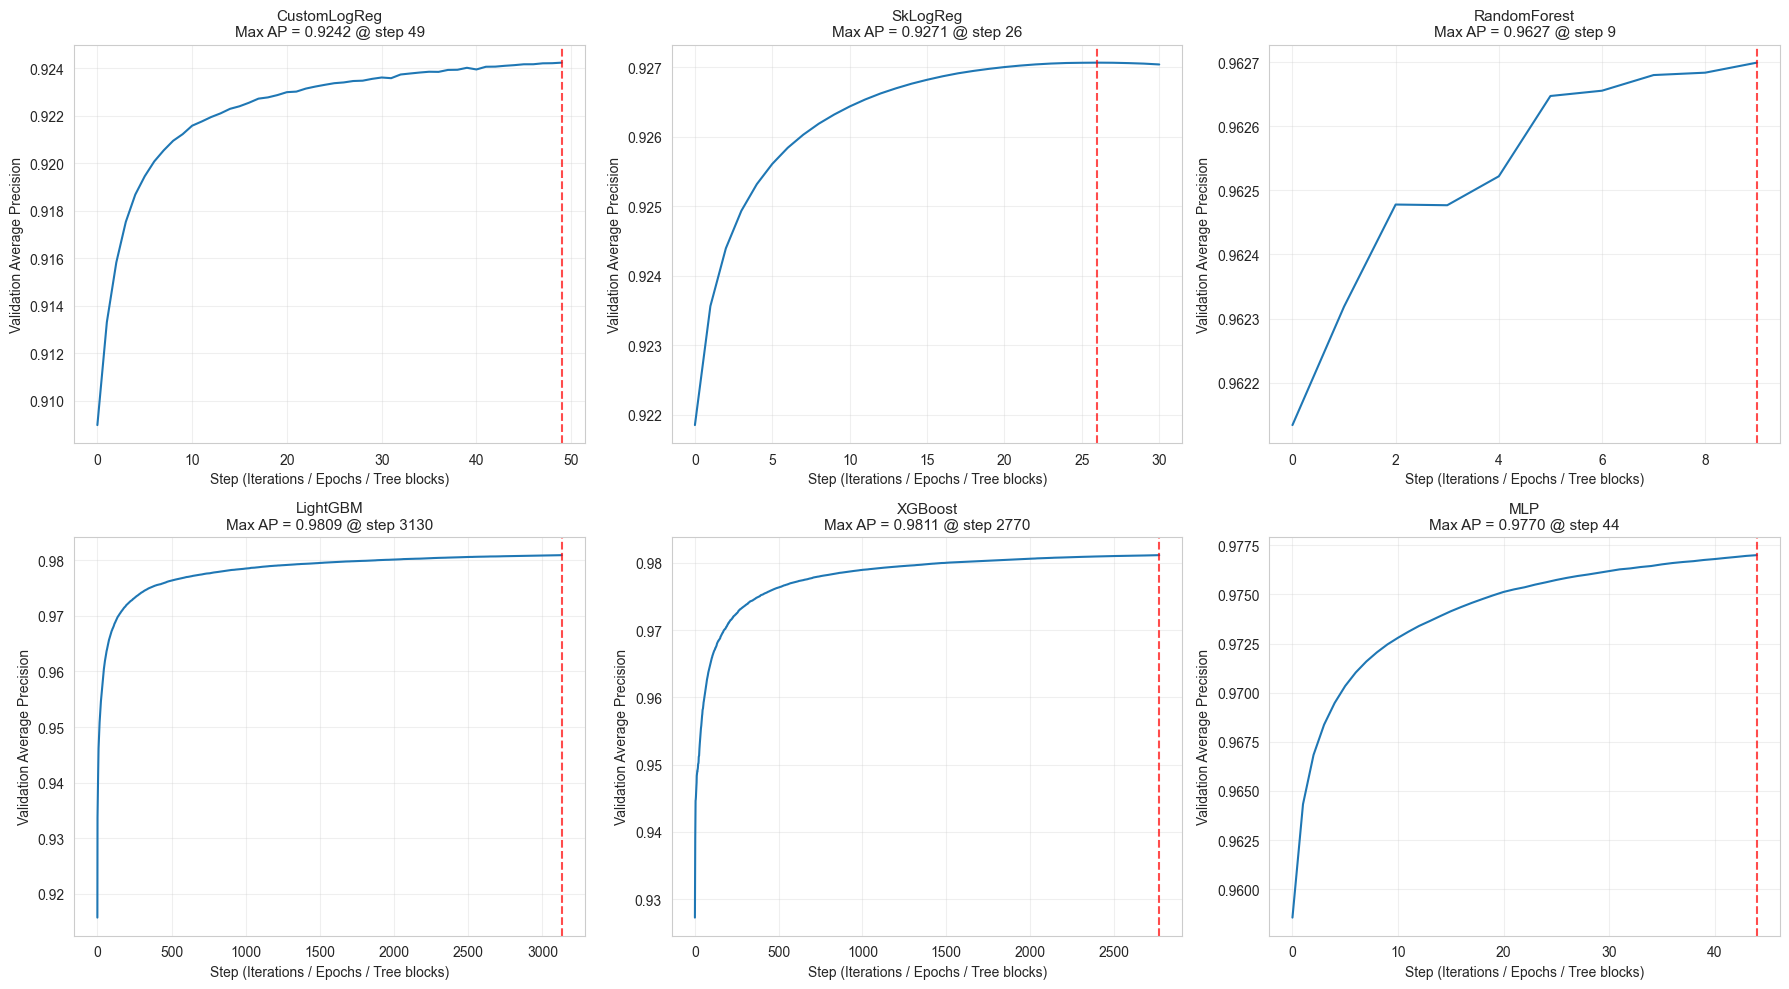

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, hist) in enumerate(eval_histories.items()):
    ax = axes[i]
    ap = hist["valid_0"]["average_precision"]
    best_i = int(np.argmax(ap))

    ax.plot(ap, linewidth=1.5)
    ax.axvline(best_i, color="r", ls="--", alpha=0.7)
    ax.set_title(f"{name}\nMax AP = {ap[best_i]:.4f} @ step {best_i}", fontsize=11)
    ax.set_xlabel("Step (Iterations / Epochs / Tree blocks)")
    ax.set_ylabel("Validation Average Precision")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/val_ap_all_models.png", dpi=140)
plt.show()

### Section 5. Thresholds & metrics

- Threshold policy: max TPR subject to FPR ≤ 1e-3 on **val** (`pick_threshold`)
- `full_metrics_block` — 17 columns: accuracy, precision, recall, f1, roc_auc, pr_auc, tpr, fpr, fp_per_million, brier, tpr@fpr ∈ {1e-2, 1e-3, 1e-4}, prec@rec ∈ {0.95, 0.99}, prec@prev ∈ {1e-3, 1e-4}
- Reported separately for `test_id` and `test_ood`
- Per-family recall on `test_ood` — exposes `suppobox-1` / `simda` / `proslikefan` failure modes

In [34]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    """Максимизирует TPR при FPR <= target_fpr. Возвращает (thr, fpr@thr, tpr@thr)."""
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def pick_threshold_at_recall(y_val, y_prob, target_recall=0.95):
    _, r, thr = precision_recall_curve(y_val, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(thr[max(idx, 0)])

In [35]:
thresholds = {}  # FPR-targeted
thresholds_recall = {}  # Recall-targeted
val_probs = {}

for name, model in trained_models.items():
    Xva = get_X(name, "val")
    y_prob = model.predict_proba(Xva)
    y_prob = y_prob[:, 1] if y_prob.ndim == 2 else y_prob
    val_probs[name] = y_prob

    thr, fpr_at, tpr_at = pick_threshold(y_val, y_prob, TARGET_FPR_VAL)
    thresholds[name] = thr

    thr_rec = pick_threshold_at_recall(y_val, y_prob, target_recall=0.95)
    thresholds_recall[name] = thr_rec

    print(
        f"{name:15s} | FPR-thr={thr:.4f} (TPR={tpr_at:.3f}) | Recall-thr={thr_rec:.4f}"
    )

CustomLogReg    | FPR-thr=0.9690 (TPR=0.317) | Recall-thr=0.1738
SkLogReg        | FPR-thr=0.9769 (TPR=0.331) | Recall-thr=0.1620
RandomForest    | FPR-thr=0.9347 (TPR=0.578) | Recall-thr=0.2312
LightGBM        | FPR-thr=0.9703 (TPR=0.657) | Recall-thr=0.2863
XGBoost         | FPR-thr=0.9725 (TPR=0.660) | Recall-thr=0.2857
MLP             | FPR-thr=0.9760 (TPR=0.624) | Recall-thr=0.2446


In [36]:
def tpr_at_fpr(y_true, y_prob, target_fpr):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def fp_per_million(fpr):
    return fpr * 1_000_000


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def full_metrics_block(y_true, y_prob, threshold):
    """17-column block. Key naming matches the original models.ipynb format
    (tpr@fpr=1e-N, prec@prev=0.001) — downstream recomputes anyway, but this
    keeps old/new artifact comparisons visually identical."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "tpr": tp / (tp + fn) if tp + fn else 0.0,
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": fp_per_million(fp / (fp + tn)) if fp + tn else 0.0,
        "brier": brier_score_loss(y_true, y_prob),
    }
    for exp in (2, 3, 4):
        m[f"tpr@fpr=1e-{exp}"] = tpr_at_fpr(y_true, y_prob, 10**-exp)
    for r in TARGET_RECALLS:
        m[f"prec@rec={r}"] = precision_at_recall(y_true, y_prob, r)
    for prev in REALISTIC_PREVALENCES:
        m[f"prec@prev={prev:g}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    return m


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out

In [37]:
test_probs = {"id": {}, "ood": {}}

for name, model in trained_models.items():
    for split in ("id", "ood"):
        Xte = get_X(name, f"test_{split}")
        p = model.predict_proba(Xte)
        p = p[:, 1] if p.ndim == 2 else p
        test_probs[split][name] = p

print("probs computed:")
for split in ("id", "ood"):
    for name in test_probs[split]:
        print(f"  {split:3s} | {name:15s} | mean={test_probs[split][name].mean():.4f}")

probs computed:
  id  | CustomLogReg    | mean=0.4531
  id  | SkLogReg        | mean=0.4573
  id  | RandomForest    | mean=0.4539
  id  | LightGBM        | mean=0.4533
  id  | XGBoost         | mean=0.4533
  id  | MLP             | mean=0.4474
  ood | CustomLogReg    | mean=0.4996
  ood | SkLogReg        | mean=0.4992
  ood | RandomForest    | mean=0.4717
  ood | LightGBM        | mean=0.4737
  ood | XGBoost         | mean=0.4729
  ood | MLP             | mean=0.4804


In [38]:
rows = []
for name in trained_models:
    m = full_metrics_block(y_test_id, test_probs["id"][name], thresholds[name])
    m["model"] = name
    rows.append(m)

metrics_id = pd.DataFrame(rows).set_index("model")
METRIC_COLS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "tpr",
    "fpr",
    "fp_per_million",
    "brier",
    "tpr@fpr=1e-2",
    "tpr@fpr=1e-3",
    "tpr@fpr=1e-4",
    "prec@rec=0.95",
    "prec@rec=0.99",
    "prec@prev=0.001",
    "prec@prev=0.0001",
]
metrics_id = metrics_id[METRIC_COLS]
print("=== test_id ===")
print(metrics_id.round(5).to_string())

=== test_id ===
              accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                      
CustomLogReg   0.69116    0.99586  0.32061  0.48505  0.92278  0.92314  0.32061  0.00111      1106.73307  0.10873       0.56129       0.30131       0.08129        0.64362        0.55774          0.22479           0.02816
SkLogReg       0.69660    0.99546  0.33279  0.49882  0.92565  0.92598  0.33279  0.00126      1260.07560  0.10665       0.56759       0.30404       0.08657        0.64812        0.56301          0.20909           0.02573
RandomForest   0.80739    0.99769  0.57680  0.73099  0.96377  0.96236  0.57680  0.00111      1106.73307 

In [39]:
rows = []
for name in trained_models:
    m = full_metrics_block(y_test_ood, test_probs["ood"][name], thresholds[name])
    m["model"] = name
    rows.append(m)

metrics_ood = pd.DataFrame(rows).set_index("model")
metrics_ood = metrics_ood[METRIC_COLS]
print("=== test_ood (novel families) ===")
print(metrics_ood.round(5).to_string())

=== test_ood (novel families) ===
              accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                      
CustomLogReg   0.64143    0.99700  0.32521  0.49044  0.91546  0.93769  0.32521  0.00111      1106.73307  0.11452       0.60943       0.29692       0.05226        0.68158        0.58231          0.22729           0.02855
SkLogReg       0.63923    0.99654  0.32121  0.48583  0.91551  0.93688  0.32121  0.00126      1260.07560  0.11535       0.58984       0.27981       0.04483        0.68858        0.57604          0.20329           0.02486
RandomForest   0.74463    0.99812  0.51970  0.68351  0.92244  0.94423  0.51970  0.0011

In [40]:
fam_recalls = {}
for name in trained_models:
    fam_recalls[name] = per_family_recall(
        df_test_ood, test_probs["ood"][name], thresholds[name]
    )

fam_df = pd.DataFrame(fam_recalls)
fam_df["mean"] = fam_df.mean(axis=1)
fam_df["type"] = fam_df.index.map(
    lambda f: (
        "wordlist"
        if f
        in [
            "gozi-gpl",
            "gozi-luther",
            "gozi-nasa",
            "gozi-rfc4343",
            "matsnu",
            "nymaim",
            "pizd",
            "suppobox-1",
            "suppobox-2",
            "suppobox-3",
            "rovnix",
        ]
        else "other"
    )
)
fam_df = fam_df.sort_values("mean")
print("=== per-family recall on test_ood ===")
print(fam_df.round(4).to_string())

=== per-family recall on test_ood ===
              CustomLogReg  SkLogReg  RandomForest  LightGBM  XGBoost     MLP    mean      type
suppobox-1          0.0000    0.0001        0.0000    0.0067   0.0095  0.0036  0.0033  wordlist
simda               0.0048    0.0036        0.0187    0.0887   0.0762  0.0675  0.0432     other
proslikefan         0.0778    0.0656        0.2038    0.3651   0.3705  0.3576  0.2401     other
pykspa              0.1540    0.1462        0.4330    0.6052   0.6064  0.5754  0.4200     other
fobber-v2           0.1428    0.1152        0.6911    0.7546   0.7547  0.6238  0.5137     other
shiotob             0.3922    0.4251        0.5769    0.5906   0.6065  0.7265  0.5530     other
dircrypt            0.5097    0.5060        0.7203    0.7680   0.7712  0.7641  0.6732     other
cryptolocker        0.5334    0.5299        0.7021    0.7482   0.7560  0.8222  0.6820     other
tinba               0.5319    0.5127        0.8026    0.8430   0.8428  0.8360  0.7281     other
mu

### Section 6. Calibration

- Isotonic regression fit on val; saved to `models/{name}_cal.pkl`
- Brier raw vs calibrated per model / per split — calibration affects Brier only, not threshold-based metrics
- Reliability diagrams: `plots/reliability_all_{id,ood}.png`

In [41]:
calibrated = {}
for name, model in trained_models.items():
    Xva = get_X(name, "val")
    p_val = model.predict_proba(Xva)[:, 1]

    iso_reg = IsotonicRegression(out_of_bounds="clip")
    iso_reg.fit(p_val, y_val)

    calibrated[name] = iso_reg
    print(f"{name:15s} | calibrated (IsotonicRegression)")

CustomLogReg    | calibrated (IsotonicRegression)
SkLogReg        | calibrated (IsotonicRegression)
RandomForest    | calibrated (IsotonicRegression)
LightGBM        | calibrated (IsotonicRegression)
XGBoost         | calibrated (IsotonicRegression)
MLP             | calibrated (IsotonicRegression)


In [42]:
for split in ("id", "ood"):
    Xte_split = "test_" + split
    y_split = y_test_id if split == "id" else y_test_ood
    print(f"--- {split} ---")
    for name, model in trained_models.items():
        p_raw = test_probs[split][name]
        # Калибруем сырые вероятности с помощью обученного изотоника
        p_cal = calibrated[name].predict(p_raw)
        print(
            f"{name:15s} | Brier raw={brier_score_loss(y_split, p_raw):.5f} "
            f"| cal={brier_score_loss(y_split, p_cal):.5f}"
        )

--- id ---
CustomLogReg    | Brier raw=0.10873 | cal=0.10791
SkLogReg        | Brier raw=0.10665 | cal=0.10557
RandomForest    | Brier raw=0.07596 | cal=0.07460
LightGBM        | Brier raw=0.05176 | cal=0.05169
XGBoost         | Brier raw=0.05150 | cal=0.05145
MLP             | Brier raw=0.05741 | cal=0.05733
--- ood ---
CustomLogReg    | Brier raw=0.11452 | cal=0.11362
SkLogReg        | Brier raw=0.11535 | cal=0.11509
RandomForest    | Brier raw=0.11156 | cal=0.11282
LightGBM        | Brier raw=0.09107 | cal=0.09131
XGBoost         | Brier raw=0.09231 | cal=0.09243
MLP             | Brier raw=0.08709 | cal=0.08624


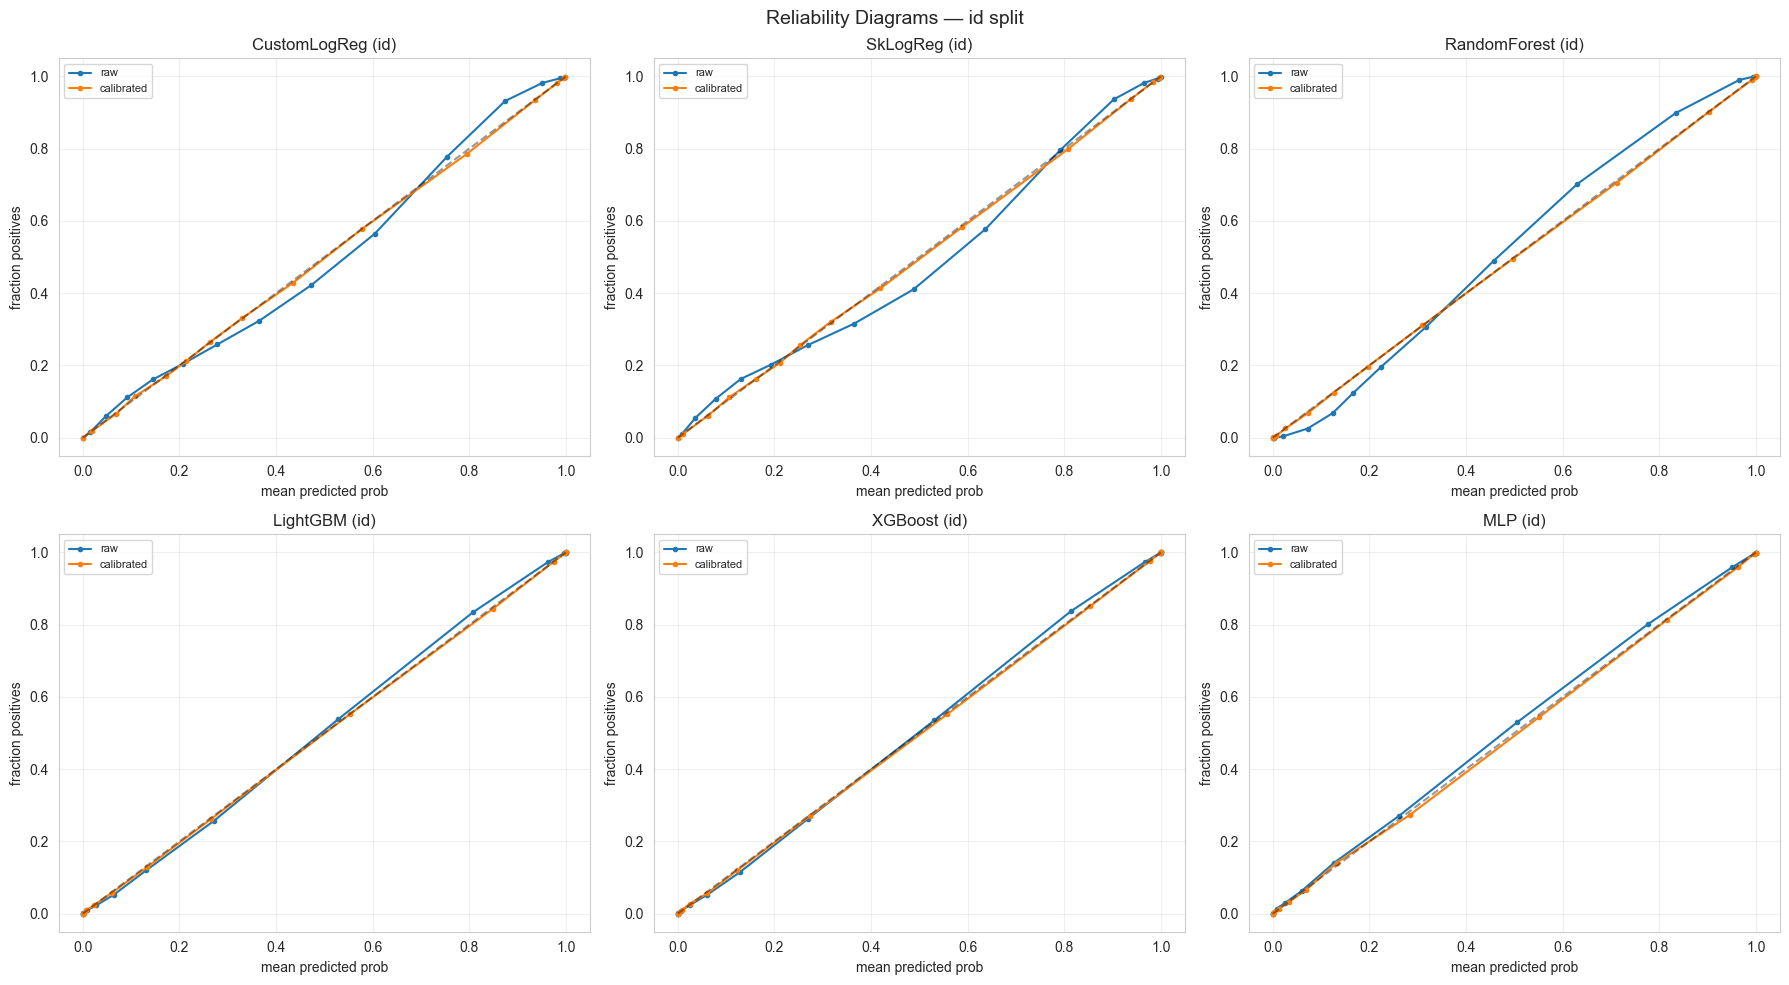

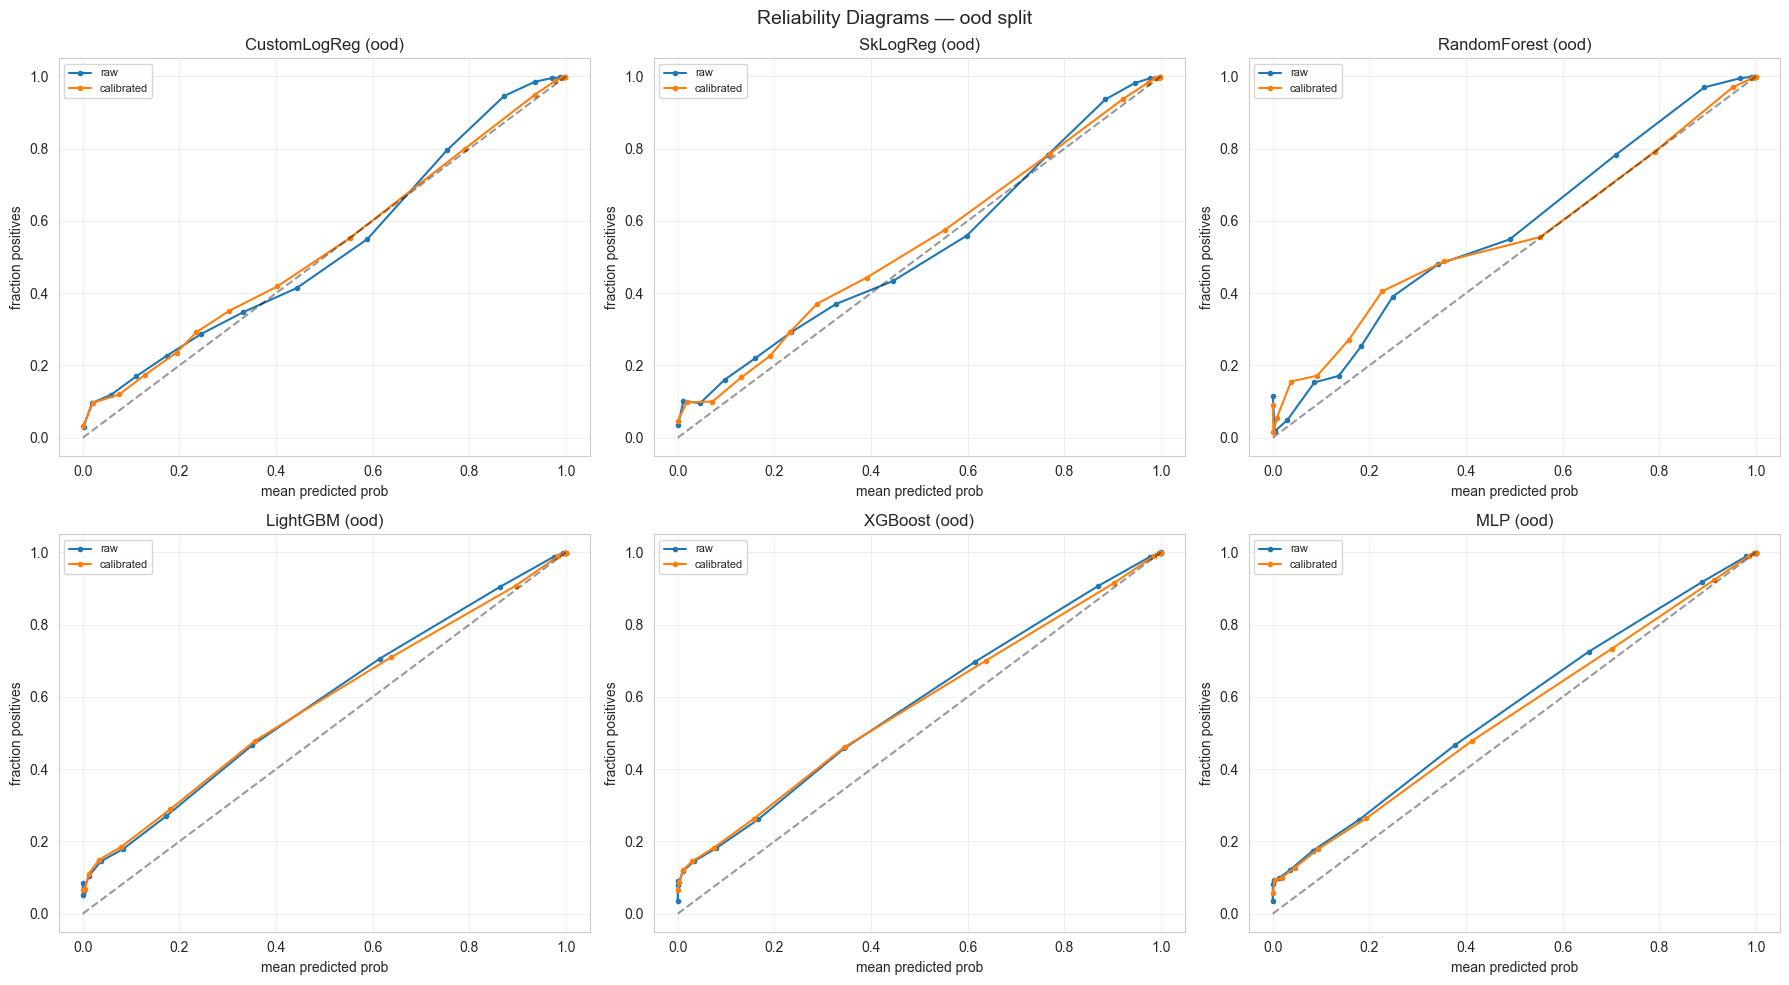

In [43]:
for split in ["id", "ood"]:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, name in enumerate(trained_models.keys()):
        ax = axes[i]
        y_true = y_test_id if split == "id" else y_test_ood
        p_raw = test_probs[split][name]
        p_cal = calibrated[name].predict(p_raw)  # Используем новый калибратор

        for label, p in [("raw", p_raw), ("calibrated", p_cal)]:
            frac_pos, mean_pred = calibration_curve(
                y_true, p, n_bins=15, strategy="quantile"
            )
            ax.plot(mean_pred, frac_pos, marker=".", label=label)

        ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax.set_title(f"{name} ({split})")
        ax.set_xlabel("mean predicted prob")
        ax.set_ylabel("fraction positives")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.suptitle(f"Reliability Diagrams — {split} split", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/reliability_all_{split}.png", dpi=140)
    plt.show()

### Section 7. Feature importance

- Native: LightGBM `gain`, XGBoost `feature_importances_`, RandomForest `feature_importances_`, LogReg coef magnitude
- Permutation importance on val (1000-sample subset, `n_repeats=3`, scoring=`average_precision`)
- SHAP: `TreeExplainer` for trees; `LinearExplainer` for LogReg; `KernelExplainer` (500 samples) for MLP
- Method comparison: `plots/importance_method_comparison_LightGBM.png`

In [44]:
print("=== Native Feature Importances ===")

native_results = {}

for name, model in trained_models.items():
    print(f"\n--- {name} ---")

    if name == "LightGBM":
        imp = pd.Series(
            model.booster_.feature_importance(importance_type="gain"),
            index=PRETRAINED_FEAT,
        )
    elif name in ["XGBoost", "RandomForest"]:
        imp = pd.Series(model.feature_importances_, index=PRETRAINED_FEAT)
    elif name in ["SkLogReg", "CustomLogReg"]:
        # For LogReg importance = abs weights (w\o bias)
        coef = model.coef_[0] if name == "SkLogReg" else model.weights[1:]
        imp = pd.Series(np.abs(coef), index=PRETRAINED_FEAT)
    elif name == "MLP":
        print("Native feature importance is not directly available for MLP.")
        continue

    native_results[name] = imp.sort_values(ascending=False)
    print(imp.sort_values(ascending=False).head(50).round(4).to_string())

=== Native Feature Importances ===

--- CustomLogReg ---
nlp_1g_dst_em     1.3972
nlp_r_sym_fqdn    1.0762
nlp_3g_pro        1.0536
nlp_2g_e          1.0255
nlp_3g_tstd       0.9918
nlp_3g_tpstd      0.9918
nlp_2g_dst_em     0.8296
nlp_l_odn         0.7983
nlp_lc_c          0.7323
nlp_1g_tsum       0.6985
nlp_lc_n          0.6903
nlp_2g_tsum       0.6763
nlp_3g_tkur       0.6200
nlp_r_sym_2dn     0.5748
nlp_3g_tsum       0.5674
nlp_2g_tstd       0.5243
nlp_2g_tpstd      0.5243
nlp_1g_sumsq      0.4931
nlp_r_num_fqdn    0.4911
nlp_1g_e          0.4823
nlp_2g_tsumsq     0.4725
nlp_1g_ske        0.4717
nlp_2g_pea        0.4627
nlp_2g_tvar       0.4522
nlp_2g_tpvar      0.4522
nlp_3g_dst_ch     0.4382
nlp_3g_dst_em     0.4068
nlp_1g_norm       0.4022
nlp_3g_var        0.3856
nlp_3g_pvar       0.3856
nlp_l_2dn         0.3825
nlp_3g_norm       0.3802
nlp_1g_pro        0.3475
nlp_r_con_odn     0.3437
nlp_1g_ken        0.3391
nlp_1g_tske       0.3190
nlp_1g_kur        0.3173
nlp_1g_rep        

In [45]:
print("=== Permutation Importance ===")

rng = np.random.RandomState(SEED)
perm_idx = rng.choice(len(X_val), size=5000, replace=False)
y_perm = y_val.iloc[perm_idx]

perm_results = {}

for name, model in trained_models.items():
    print(f"\n--- {name} ---")
    X_perm = X_val_s.iloc[perm_idx] if MODELS[name]["scale"] else X_val.iloc[perm_idx]

    perm = permutation_importance(
        model,
        X_perm,
        y_perm,
        scoring="average_precision",
        n_repeats=3,
        random_state=SEED,
        n_jobs=-1,
    )
    perm_series = pd.Series(perm.importances_mean, index=PRETRAINED_FEAT).sort_values(
        ascending=False
    )
    perm_results[name] = perm_series

    print(perm_series.sort_values(ascending=False).head(50).round(4).to_string())

=== Permutation Importance ===

--- CustomLogReg ---
nlp_1g_dst_em     0.0986
nlp_r_sym_fqdn    0.0592
nlp_2g_e          0.0540
nlp_3g_pro        0.0508
nlp_3g_tstd       0.0447
nlp_3g_tpstd      0.0447
nlp_lc_c          0.0313
nlp_l_odn         0.0268
nlp_2g_tsum       0.0240
nlp_2g_dst_em     0.0236
nlp_1g_tsum       0.0220
nlp_3g_tkur       0.0212
nlp_3g_tsum       0.0201
nlp_2g_tsumsq     0.0143
nlp_lc_n          0.0140
nlp_2g_tpstd      0.0137
nlp_2g_tstd       0.0137
nlp_2g_tpvar      0.0133
nlp_2g_tvar       0.0133
nlp_1g_ske        0.0129
nlp_1g_sumsq      0.0116
nlp_1g_e          0.0114
nlp_r_num_fqdn    0.0105
nlp_r_sym_2dn     0.0104
nlp_2g_pea        0.0074
nlp_1g_pro        0.0072
nlp_r_con_odn     0.0070
nlp_3g_dst_em     0.0066
nlp_3g_norm       0.0063
nlp_l_2dn         0.0063
nlp_1g_norm       0.0061
nlp_3g_dst_ch     0.0061
nlp_3g_tsumsq     0.0048
nlp_3g_tpvar      0.0048
nlp_3g_tvar       0.0048
nlp_3g_var        0.0044
nlp_3g_pvar       0.0044
nlp_r_con_2dn     0.00

In [46]:
print("=== SHAP Values ===")

rng = np.random.RandomState(SEED)

shap_results = {}

# For MLP (KernelSHAP) take less
idx_small = rng.choice(len(X_val), size=500, replace=False)
idx_large = rng.choice(len(X_val), size=5000, replace=False)

for name, model in trained_models.items():
    print(f"\n--- {name} ---")

    if name in ["LightGBM", "XGBoost", "RandomForest"]:
        X_shap = X_val.iloc[idx_large]
        explainer = shap.TreeExplainer(model)
        shap_vals = explainer.shap_values(X_shap)

    elif name in ["SkLogReg", "CustomLogReg"]:
        X_shap = (
            X_val_s.iloc[idx_large] if MODELS[name]["scale"] else X_val.iloc[idx_large]
        )
        # Use LinearExplainer for LogRegs
        masker = shap.maskers.Independent(X_shap, max_samples=100)
        explainer = shap.LinearExplainer(model, masker)
        shap_vals = explainer.shap_values(X_shap)

    elif name == "MLP":
        X_shap = X_val_s.iloc[idx_small]
        print(
            f"  (Using KernelSHAP on {len(X_shap)} samples, this may take a minute...)"
        )
        # Background set for MLP
        background = shap.sample(X_val_s, 50)
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_vals = explainer.shap_values(X_shap, nsamples=100)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
    elif len(shap_vals.shape) == 3:  # Some versions return (n, features, classes)
        shap_vals = shap_vals[:, :, 1]

    shap_series = pd.Series(
        np.abs(shap_vals).mean(axis=0), index=PRETRAINED_FEAT
    ).sort_values(ascending=False)
    shap_results[name] = shap_series

    print(shap_series.sort_values(ascending=False).head(50).round(4).to_string())

Background dataset has 5000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5000 when initializing the masker.


Background dataset has 5000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5000 when initializing the masker.


=== SHAP Values ===

--- CustomLogReg ---
nlp_1g_dst_em     1.1447
nlp_r_sym_fqdn    0.7783
nlp_2g_e          0.7606
nlp_2g_dst_em     0.6822
nlp_3g_pro        0.6003
nlp_1g_tsum       0.5673
nlp_lc_c          0.5563
nlp_3g_tkur       0.5527
nlp_2g_tsum       0.5101
nlp_3g_tstd       0.4902
nlp_3g_tpstd      0.4902
nlp_lc_n          0.4373
nlp_2g_tstd       0.4258
nlp_2g_tpstd      0.4258
nlp_l_odn         0.3801
nlp_1g_e          0.3689
nlp_1g_ske        0.3656
nlp_2g_pea        0.3615
nlp_1g_norm       0.3574
nlp_1g_sumsq      0.3543
nlp_r_num_fqdn    0.3422
nlp_3g_dst_em     0.3411
nlp_3g_tsum       0.3375
nlp_2g_tsumsq     0.3319
nlp_2g_tvar       0.3180
nlp_2g_tpvar      0.3180
nlp_l_2dn         0.3002
nlp_3g_dst_ch     0.2884
nlp_1g_ken        0.2670
nlp_1g_pro        0.2649
nlp_3g_var        0.2511
nlp_3g_pvar       0.2511
nlp_1g_rep        0.2506
nlp_3g_norm       0.2474
nlp_1g_tske       0.2374
nlp_1g_kur        0.2304
nlp_r_sym_2dn     0.2177
nlp_1g_dst_kl     0.2162
nlp_2g_c

c:\Users\pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


nlp_l_2dn         1.3617
nlp_3g_e          1.3295
nlp_3g_norm       0.7784
nlp_1g_dst_em     0.7611
nlp_lc_c          0.7195
nlp_2g_norm       0.5460
nlp_r_sym_fqdn    0.4879
nlp_2g_e          0.4834
nlp_2g_dst_em     0.4665
nlp_r_con_2dn     0.4540
nlp_3g_tpstd      0.4070
nlp_r_let_fqdn    0.3788
nlp_3g_dst_eu     0.3677
nlp_3g_dst_em     0.3113
nlp_3g_ken        0.2897
nlp_1g_norm       0.2880
nlp_1g_dst_ca     0.2641
nlp_r_vow_fqdn    0.2583
nlp_r_con_fqdn    0.2384
nlp_r_vow_2dn     0.2194
nlp_3g_pstd       0.2140
nlp_3g_tsumsq     0.2086
nlp_3g_dst_ca     0.2041
nlp_2g_tpstd      0.2038
nlp_2g_dst_eu     0.1935
nlp_lc_n          0.1765
nlp_1g_tpstd      0.1662
nlp_1g_tske       0.1617
nlp_3g_tkur       0.1600
nlp_lc_v          0.1577
nlp_3g_tpvar      0.1544
nlp_2g_tsumsq     0.1540
nlp_1g_tkur       0.1456
nlp_2g_pro        0.1449
nlp_l_fqdn        0.1342
nlp_2g_tkur       0.1308
nlp_3g_ske        0.1291
nlp_3g_pro        0.1268
nlp_2g_tsum       0.1253
nlp_r_num_fqdn    0.1212


  0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


nlp_3g_e          0.0662
nlp_2g_e          0.0650
nlp_l_odn         0.0408
nlp_1g_dst_em     0.0373
nlp_r_sym_fqdn    0.0282
nlp_r_num_fqdn    0.0230
nlp_2g_dst_em     0.0173
nlp_l_2dn         0.0157
nlp_1g_tsum       0.0147
nlp_1g_tske       0.0108
nlp_r_vow_odn     0.0101
nlp_2g_pea        0.0095
nlp_r_num_2dn     0.0095
nlp_2g_tpstd      0.0091
nlp_r_let_2dn     0.0086
nlp_2g_pro        0.0086
nlp_3g_norm       0.0082
nlp_3g_pvar       0.0073
nlp_lc_c          0.0073
nlp_lc_n          0.0070
nlp_1g_tsumsq     0.0060
nlp_1g_dst_ca     0.0060
nlp_3g_var        0.0059
nlp_3g_tpstd      0.0059
nlp_2g_tvar       0.0058
nlp_3g_tstd       0.0057
nlp_r_vow_fqdn    0.0055
nlp_3g_dst_em     0.0055
nlp_3g_cov        0.0054
nlp_3g_dst_ji     0.0053
nlp_2g_dist       0.0053
nlp_2g_cov        0.0052
nlp_3g_dst_eu     0.0051
nlp_2g_spe        0.0050
nlp_1g_sumsq      0.0048
nlp_1g_norm       0.0048
nlp_3g_dst_kl     0.0048
nlp_1g_qmean      0.0048
nlp_2g_tsum       0.0048
nlp_1g_tpvar      0.0047


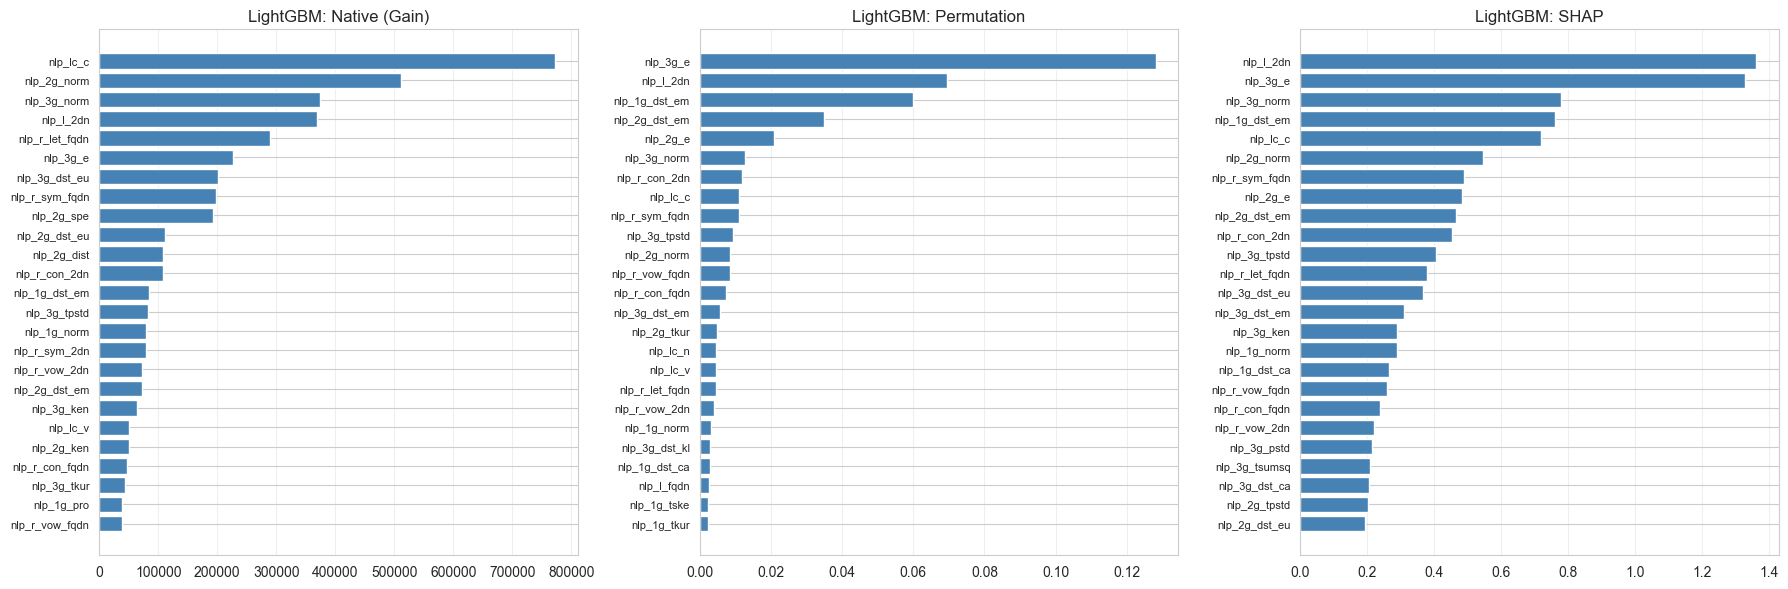

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
model_name = "LightGBM"

for ax, (title, results) in zip(
    axes,
    [
        ("Native (Gain)", native_results.get(model_name)),
        ("Permutation", perm_results.get(model_name)),
        ("SHAP", shap_results.get(model_name)),
    ],
):
    if results is not None:
        top = results.head(25)[::-1]
        ax.barh(range(len(top)), top.values, color="steelblue")
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(top.index, fontsize=8)
        ax.set_title(f"{model_name}: {title}")
        ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{PATHS['plots_dir']}/importance_method_comparison_{model_name}.png", dpi=140
)
plt.show()

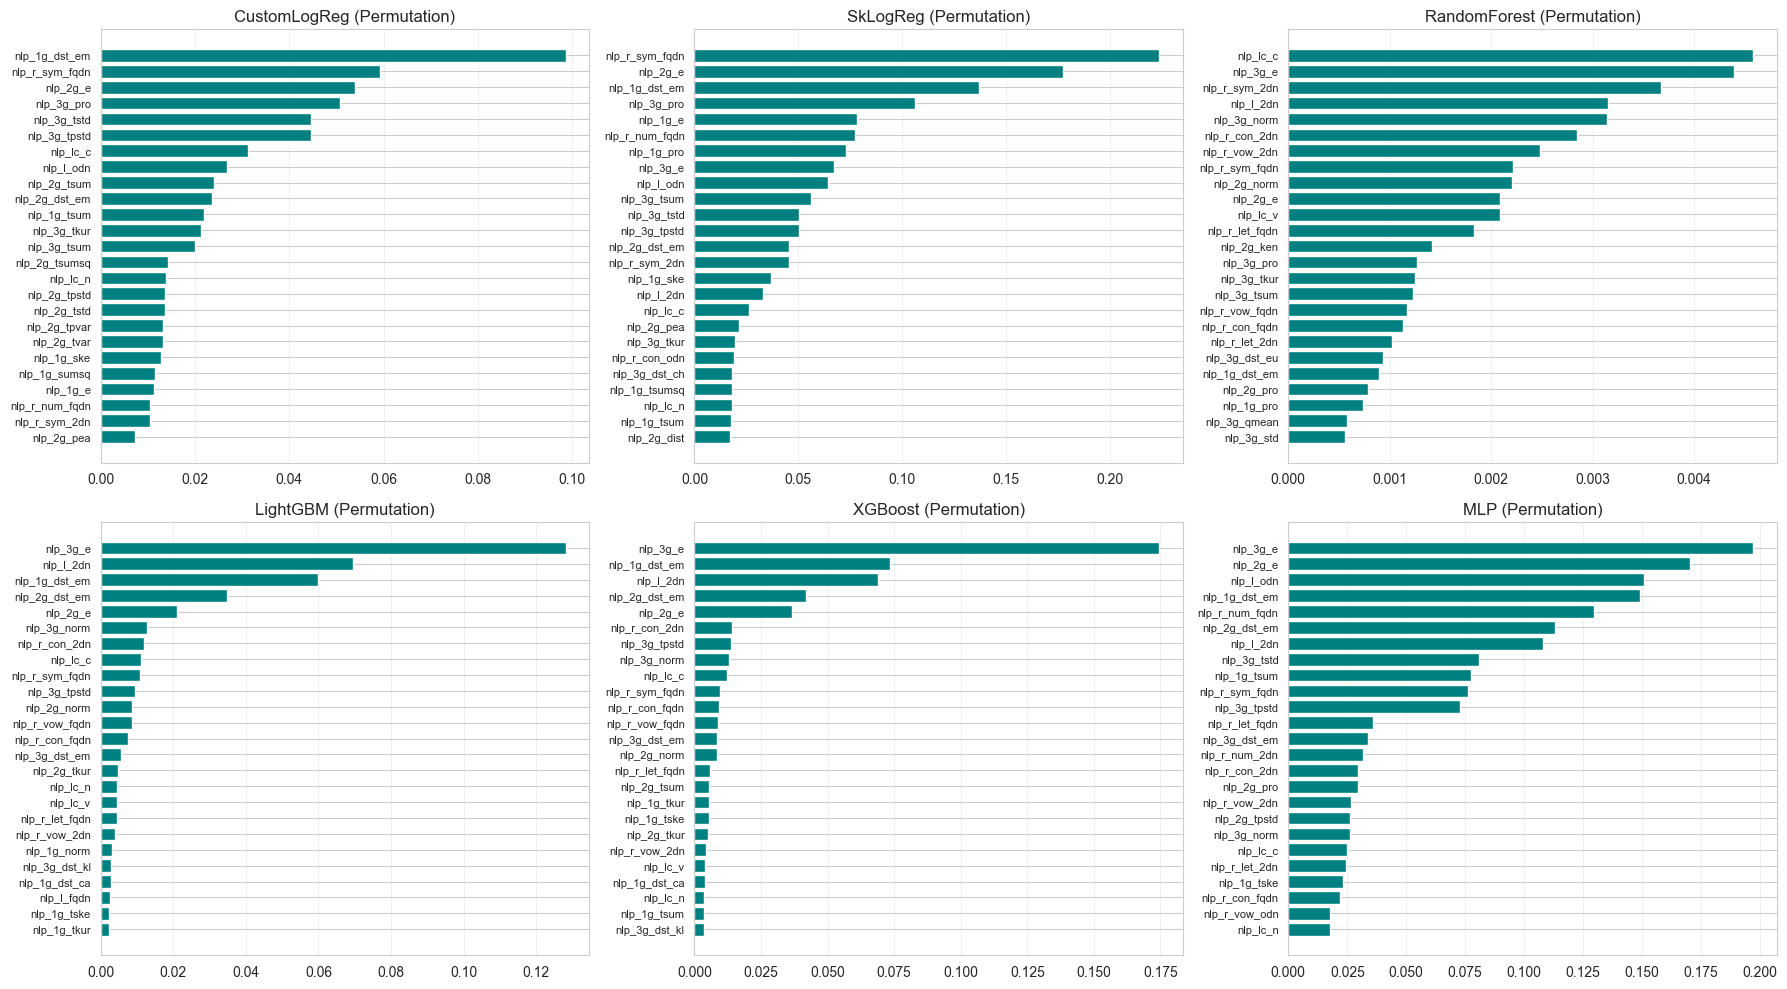

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, s) in enumerate(perm_results.items()):
    ax = axes[i]
    top = s.head(25)[::-1]
    ax.barh(range(len(top)), top.values, color="teal")
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=8)
    ax.set_title(f"{name} (Permutation)")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/permutation_all_models.png", dpi=140)
plt.show()

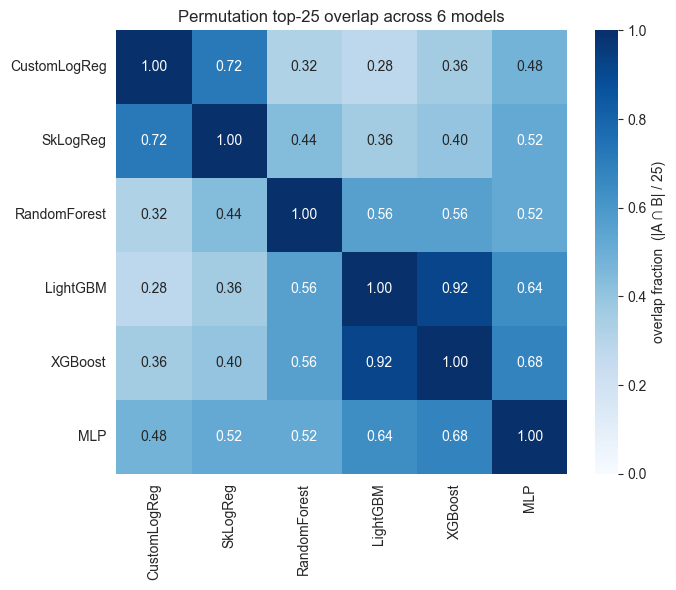

Features in top-25 across all 6 models (Permutation): 4
['nlp_1g_dst_em', 'nlp_2g_e', 'nlp_r_sym_fqdn', 'nlp_lc_c']


In [49]:
model_names = list(perm_results.keys())
top_sets = {name: set(s.head(25).index) for name, s in perm_results.items()}

overlap = pd.DataFrame(0.0, index=model_names, columns=model_names, dtype=float)
for m1 in model_names:
    for m2 in model_names:
        overlap.loc[m1, m2] = len(top_sets[m1] & top_sets[m2]) / 25.0

_fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    overlap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    cbar_kws={"label": "overlap fraction  (|A ∩ B| / 25)"},
    ax=ax,
)
ax.set_title("Permutation top-25 overlap across 6 models")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "permutation_overlap_heatmap.png", dpi=140)
plt.show()

common_all = set.intersection(*top_sets.values())
print(f"Features in top-25 across all 6 models (Permutation): {len(common_all)}")
print(list(common_all))

### Section 8. Error analysis

- Top FP / FN on `test_ood` per model, saved to `models/errors/{name}_ood_{FP,FN}.csv`
- FN by family — aggregate FN count across 6 models (lower bound for classical detection)

In [50]:
def save_top_errors(name, y_true, df, y_prob, threshold, out_dir, n=10):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    y_true_arr = (
        y_true.to_numpy() if hasattr(y_true, "to_numpy") else np.asarray(y_true)
    )
    pred = (y_prob >= threshold).astype(int)
    fp_mask = (y_true_arr == 0) & (pred == 1)
    fn_mask = (y_true_arr == 1) & (pred == 0)

    fp = (
        df.loc[fp_mask, ["domain", "class"]]
        .assign(prob=y_prob[fp_mask])
        .sort_values("prob", ascending=False)
    )
    fn = (
        df.loc[fn_mask, ["domain", "class"]]
        .assign(prob=y_prob[fn_mask])
        .sort_values("prob", ascending=True)
    )
    fp.head(n).to_csv(out_dir / f"{name}_ood_FP.csv", index=False)
    fn.head(n).to_csv(out_dir / f"{name}_ood_FN.csv", index=False)
    return fp.head(n), fn.head(n)


errors_dir = Path(PATHS["models_dir"]) / "errors"
all_errors = {}
for name in trained_models:
    fp, fn = save_top_errors(
        name,
        y_test_ood,
        df_test_ood,
        test_probs["ood"][name],
        thresholds[name],
        errors_dir,
        n=10,
    )
    all_errors[name] = {"FP": fp, "FN": fn}
    print(f"\n=== {name} (test_ood) ===")
    print(f"FP count = {len(fp)} | FN count = {len(fn)}")
    print("Top FP:")
    print(fp.to_string(index=False))
    print("Top FN:")
    print(fn.to_string(index=False))

print(f"\nErrors saved to {errors_dir}")


=== CustomLogReg (test_ood) ===
FP count = 10 | FN count = 10
Top FP:
                                                      domain class     prob
omgomgomg5j4yrr4mjdv3h5c5xfvxtqqs2in7smi65mjps7wvkmqmtqd.com legit 0.999997
            xn-----6kcdfldbfd2aga1bqjlbbb4b4d7d1fzd.xn--p1ai legit 0.999957
                                        jxpxkyjtyxzrgszyy.cn legit 0.999946
                        xn-----7kchclcsdcvgr8afcd9cqkh2f.com legit 0.999819
                          xn--b1aedfedwqbdfbnzkf0oe.xn--p1ai legit 0.999696
                              xn--vk1b87o4zefwd.xn--3e0b707e legit 0.999417
                                 xn--hy1bv1e8tk46a75kztd.com legit 0.999304
                  xn--80abacdnj3a5afcccbrk3g3a2gd7d.xn--p1ai legit 0.999259
                             xn--980bx8aa741fo5glrhi5eh1b.kr legit 0.999150
                            xn--9z2b23n2e4a724cgvlx0h23g.com legit 0.998939
Top FN:
  domain class         prob
qeqeq.eu simda 6.502756e-07
pupup.eu simda 9.783887e-05
g

In [51]:
fn_summary = pd.DataFrame()

for name in trained_models:
    preds = (test_probs["ood"][name] >= thresholds[name]).astype(int)
    fn_mask = (df_test_ood["label"] == 1) & (preds == 0)

    fn_fams = df_test_ood.loc[fn_mask, "class"].value_counts()
    fn_summary[name] = fn_fams

fn_summary = fn_summary.fillna(0).astype(int)

fn_summary["Total_FN_All_Models"] = fn_summary.sum(axis=1)
fn_summary = fn_summary.sort_values("Total_FN_All_Models", ascending=False)

print("=== False Negatives by Family (test_ood) ===")
print(fn_summary.to_string())

worst_family = fn_summary.index[0]
print(f"\nDomain examples for worst family ({worst_family}):")
samples = df_test_ood[df_test_ood["class"] == worst_family]["domain"].head(10).tolist()
print(samples)

=== False Negatives by Family (test_ood) ===
              CustomLogReg  SkLogReg  RandomForest  LightGBM  XGBoost    MLP  Total_FN_All_Models
class                                                                                            
simda                19903     19929         19626     18227    18476  18650               114811
proslikefan          18444     18689         15923     12697    12590  12849                91192
fobber-v2            17143     17696          6179      4909     4906   7525                58358
suppobox-1            9556      9555          9556      9492     9465   9522                57146
shiotob              12156     11498          8462      8189     7870   5470                53645
dircrypt              9807      9879          5594      4639     4577   4718                39214
cryptolocker          9331      9402          5958      5037     4880   3555                38163
pykspa                8460      8538          5670      3948     3936   4

### Section 9. Latency

- `single_ms` (warm-up 20, repeats 200), `batch_1024_s`, `throughput_domains_s`, `model_size_mb` (via `io.BytesIO + joblib.dump`)
- Same protocol as `e2e_models` / `models_optimization` — numbers are directly comparable

In [52]:
def benchmark_single(model, X_one, n_warm=LATENCY_WARMUP, n=LATENCY_REPEATS):
    for _ in range(n_warm):
        model.predict_proba(X_one)
    t0 = time.perf_counter()
    for _ in range(n):
        model.predict_proba(X_one)
    return (time.perf_counter() - t0) / n * 1000


def benchmark_batch(model, X_batch, n_warm=5, n=20):
    for _ in range(n_warm):
        model.predict_proba(X_batch)
    t0 = time.perf_counter()
    for _ in range(n):
        model.predict_proba(X_batch)
    return (time.perf_counter() - t0) / n


latency = {}
for name, model in trained_models.items():
    Xte = get_X(name, "test_ood")
    X_one = Xte.iloc[:1]
    X_batch = Xte.iloc[:1024]

    ms_single = benchmark_single(model, X_one)
    s_batch = benchmark_batch(model, X_batch)

    _buf = io.BytesIO()
    joblib.dump(model, _buf)
    _size_mb = _buf.tell() / 1e6
    del _buf

    latency[name] = {
        "single_ms": ms_single,
        "batch_1024_s": s_batch,
        "throughput_domains_s": 1024 / s_batch,
        "model_size_mb": _size_mb,
    }
    print(
        f"{name:15s} | single={ms_single:7.3f} ms | batch1024={s_batch:6.3f} s | "
        f"throughput={1024 / s_batch:8.0f} dom/s | size={_size_mb:.2f} MB"
    )

lat_df = pd.DataFrame(latency).T
print("\n=== Latency Summary ===")
print(lat_df.round(3).to_string())

CustomLogReg    | single=  0.043 ms | batch1024= 0.001 s | throughput= 1094052 dom/s | size=0.00 MB
SkLogReg        | single=  0.803 ms | batch1024= 0.001 s | throughput= 1060003 dom/s | size=0.01 MB
RandomForest    | single= 28.895 ms | batch1024= 0.029 s | throughput=   35605 dom/s | size=68.25 MB
LightGBM        | single=  1.350 ms | batch1024= 0.017 s | throughput=   59320 dom/s | size=10.48 MB
XGBoost         | single=  4.112 ms | batch1024= 0.012 s | throughput=   83305 dom/s | size=10.41 MB
MLP             | single=  0.982 ms | batch1024= 0.020 s | throughput=   52017 dom/s | size=0.28 MB

=== Latency Summary ===
              single_ms  batch_1024_s  throughput_domains_s  model_size_mb
CustomLogReg      0.043         0.001           1094052.171          0.004
SkLogReg          0.803         0.001           1060002.997          0.005
RandomForest     28.895         0.029             35605.415         68.254
LightGBM          1.350         0.017             59319.626         10.4

### Section 10. Cross-validation

- 5-fold `GroupKFold` on `cv_fold_indices.npz` — same folds as `e2e_models` and `models_optimization`
- Each fold uses the **same fit protocol as deployed models** (identical to Section 4)
- Fold-level JSON cache: `models/cv_feature/{name}/fold{k}.json`; summary cache: `.../summary.csv`
- First run ≈ 75 min; subsequent runs hit cache (seconds). `CACHE_RESET=True` to invalidate.
- Reported: `roc_auc`, `pr_auc`, `tpr@fpr=1e-3` mean ± std across folds

In [53]:
def cv_fold_train(name, X_tr_raw, y_tr, X_va_raw, y_va):
    """Train one fold with the same config as the deployed model (7.1.x)."""
    cfg = MODELS[name]
    if cfg["scale"]:
        sc = StandardScaler().fit(X_tr_raw)
        X_tr = pd.DataFrame(
            sc.transform(X_tr_raw), columns=X_tr_raw.columns, index=X_tr_raw.index
        )
        X_va = pd.DataFrame(
            sc.transform(X_va_raw), columns=X_va_raw.columns, index=X_va_raw.index
        )
    else:
        sc = None
        X_tr, X_va = X_tr_raw, X_va_raw

    model = cfg["builder"]()
    if name == "CustomLogReg":
        model.fit(X_tr.values, y_tr, eval_set=[(X_va.values, y_va)])
    elif name == "SkLogReg":
        rng = np.random.RandomState(SEED)
        for _ in range(50):
            idx = rng.permutation(len(X_tr))
            model.partial_fit(X_tr.iloc[idx], y_tr.iloc[idx], classes=[0, 1])
    elif name == "RandomForest":
        for _ in range(10):
            model.set_params(n_estimators=model.n_estimators + 10)
            model.fit(X_tr, y_tr)
    elif name == "LightGBM":
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="average_precision",
            callbacks=[
                lgb.early_stopping(200, min_delta=1e-4, verbose=False),
                lgb.log_evaluation(0),
            ],
        )
    elif name == "XGBoost":
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    elif name == "MLP":
        model, _ = fit_mlp_with_early_stop(
            model,
            X_tr.values,
            y_tr.values,
            X_va.values,
            y_va.values,
            max_epochs=45,
            patience=5,
            min_delta=1e-4,
            verbose=False,
        )
    return model, sc


def cv_run_cached(name, X_full, y_full, groups, n_splits=5, target_fpr=1e-3):
    """GroupKFold with fold-level + summary caching. Returns per-fold metrics DataFrame."""
    out_dir = Path(PATHS["cv_feature_dir"]) / name
    out_dir.mkdir(parents=True, exist_ok=True)
    summary_path = out_dir / "summary.csv"

    if CV_USE_SUMMARY_CACHE and summary_path.exists() and not CACHE_RESET:
        df = pd.read_csv(summary_path)
        print(f"  [{name}] loaded {len(df)} folds from {summary_path.name}")
        return df.set_index("fold") if "fold" in df.columns else df

    gkf = GroupKFold(n_splits=n_splits)
    rows = []
    for k, (tr_pos, va_pos) in enumerate(gkf.split(X_full, y_full, groups)):
        fold_json = out_dir / f"fold{k}.json"
        if CV_FOLD_RESUME and fold_json.exists() and not CACHE_RESET:
            with open(fold_json) as f:
                row = json.load(f)
            rows.append(row)
            print(f"  [{name} fold {k}] cached: AP={row['pr_auc']:.4f}")
            continue

        X_tr_raw = X_full.iloc[tr_pos]
        X_va_raw = X_full.iloc[va_pos]
        y_tr = y_full.iloc[tr_pos]
        y_va = y_full.iloc[va_pos]

        model, sc = cv_fold_train(name, X_tr_raw, y_tr, X_va_raw, y_va)
        X_va = (
            pd.DataFrame(
                sc.transform(X_va_raw), columns=X_va_raw.columns, index=X_va_raw.index
            )
            if sc is not None
            else X_va_raw
        )
        p = model.predict_proba(X_va)[:, 1]

        row = {
            "fold": int(k),
            "roc_auc": float(roc_auc_score(y_va, p)),
            "pr_auc": float(average_precision_score(y_va, p)),
            f"tpr@fpr{target_fpr}": float(tpr_at_fpr(y_va, p, target_fpr)),
        }
        with open(fold_json, "w") as f:
            json.dump(row, f, indent=2)
        rows.append(row)
        print(
            f"  [{name} fold {k}] AP={row['pr_auc']:.4f} | TPR@1e-3={row[f'tpr@fpr{target_fpr}']:.4f}"
        )

    df = pd.DataFrame(rows).set_index("fold")
    df.to_csv(summary_path)
    return df

In [54]:
cv_idx_local = np.concatenate([train_idx, val_idx, test_id_idx])
X_cv = full_df.loc[cv_idx_local, PRETRAINED_FEAT].astype("float32")
y_cv = y_all[cv_idx_local]
g_cv = full_df.loc[cv_idx_local, "class"].values.astype(object).copy()

legit_mask = g_cv == "legit"
domain_cv = full_df.loc[cv_idx_local, "domain"].values
legit_hashes = pd.util.hash_array(domain_cv[legit_mask]) % N_LEGIT_GROUPS
g_cv[legit_mask] = np.array([f"legit_{h}" for h in legit_hashes])

print(f"CV: {len(X_cv)} rows | {len(np.unique(g_cv))} groups | {N_CV_SPLITS} folds")

cv_results = {}
for name in MODELS:
    print(f"\nCV {name}...")
    t0 = time.perf_counter()
    cv_results[name] = cv_run_cached(
        name,
        X_cv,
        y_cv,
        g_cv,
        n_splits=N_CV_SPLITS,
        target_fpr=TARGET_FPR_VAL,
    )
    print(f"  done in {time.perf_counter() - t0:.1f}s")

cv_df = pd.DataFrame(
    {
        name: {
            "roc_auc_mean": res["roc_auc"].mean(),
            "roc_auc_std": res["roc_auc"].std(),
            "pr_auc_mean": res["pr_auc"].mean(),
            "pr_auc_std": res["pr_auc"].std(),
            f"tpr@fpr{TARGET_FPR_VAL}_mean": res[f"tpr@fpr{TARGET_FPR_VAL}"].mean(),
            f"tpr@fpr{TARGET_FPR_VAL}_std": res[f"tpr@fpr{TARGET_FPR_VAL}"].std(),
        }
        for name, res in cv_results.items()
    }
).T

print("\n=== GroupKFold CV (5 folds, family-aware) ===")
print(cv_df.round(5).to_string())

del X_cv, g_cv
gc.collect()

CV: 1830364 rows | 50 groups | 5 folds

CV CustomLogReg...
  [CustomLogReg] loaded 5 folds from summary.csv
  done in 0.0s

CV SkLogReg...
  [SkLogReg] loaded 5 folds from summary.csv
  done in 0.0s

CV RandomForest...
  [RandomForest] loaded 5 folds from summary.csv
  done in 0.0s

CV LightGBM...
  [LightGBM] loaded 5 folds from summary.csv
  done in 0.0s

CV XGBoost...
  [XGBoost] loaded 5 folds from summary.csv
  done in 0.0s

CV MLP...
  [MLP fold 0] AP=0.8556 | TPR@1e-3=0.3766
  [MLP fold 1] AP=0.9114 | TPR@1e-3=0.3772
  [MLP fold 2] AP=0.9411 | TPR@1e-3=0.5425
  [MLP fold 3] AP=0.8679 | TPR@1e-3=0.2790
  [MLP fold 4] AP=0.9623 | TPR@1e-3=0.6559
  done in 5859.7s

=== GroupKFold CV (5 folds, family-aware) ===
              roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  tpr@fpr0.001_mean  tpr@fpr0.001_std
CustomLogReg       0.87274      0.06542      0.87812     0.05952            0.26832           0.12422
SkLogReg           0.88063      0.06088      0.88429     0.05732        

42972

### Section 11. Artifact & summary

- Save `models/{name}.pkl` + `{name}_cal.pkl` for all 6 models
- `model_artifact.json`: features, thresholds, held-out families, `production_candidates=["LightGBM","XGBoost","MLP"]`, `explored_models=["CustomLogReg","SkLogReg","RandomForest"]`, 17-col metrics (id/ood), latency, versions
- ROC / PR / CM plots and side-by-side id-vs-ood summary for all 6 models
- Artifact thresholds are the source of truth for downstream (`e2e_models` asserts on them)

In [55]:
for name, model in trained_models.items():
    joblib.dump(model, f"{PATHS['models_dir']}/{name}.pkl")
    joblib.dump(calibrated[name], f"{PATHS['models_dir']}/{name}_cal.pkl")

artifact = {
    "feature_cols": PRETRAINED_FEAT,
    "base_feature_cols": feature_cols,
    "isnan_cols": isnan_cols,
    "thresholds": thresholds,
    "held_families": list(held_families),
    "target_fpr_val": TARGET_FPR_VAL,
    "seed": SEED,
    "production_candidates": ["LightGBM", "XGBoost", "MLP"],
    "explored_models": ["CustomLogReg", "SkLogReg", "RandomForest"],
    "metrics_id": metrics_id.round(6).to_dict(orient="index"),
    "metrics_ood": metrics_ood.round(6).to_dict(orient="index"),
    "latency": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in latency.items()},
    "versions": {
        "sklearn": sklearn.__version__,
        "lightgbm": lgb.__version__,
        "xgboost": xgb.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "shap": shap.__version__,
    },
}
with open(PATHS["artifact"], "w", encoding="utf-8") as f:
    json.dump(artifact, f, ensure_ascii=False, indent=2, default=float)

print("Artifact saved:", PATHS["artifact"])
print("Models saved to:", PATHS["models_dir"])

Artifact saved: d:\Data\Scripts\model_artifact.json
Models saved to: d:\Data\Scripts\models


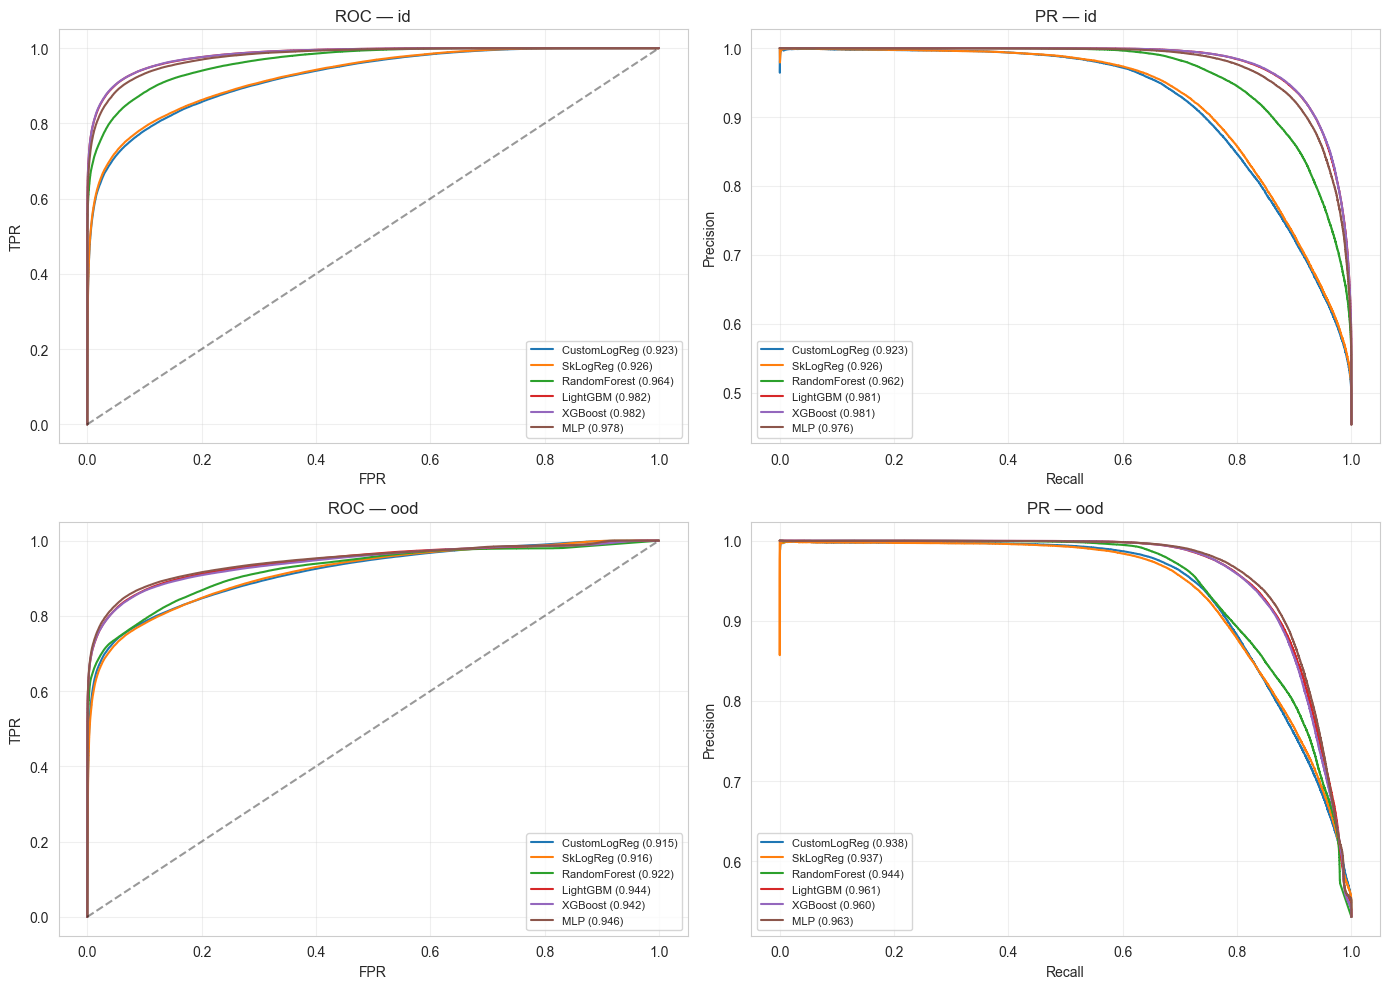

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, split in zip(axes[:, 0], ["id", "ood"]):
    y_true = y_test_id if split == "id" else y_test_ood
    for name in trained_models:
        fpr, tpr, _ = roc_curve(y_true, test_probs[split][name])
        auc = roc_auc_score(y_true, test_probs[split][name])
        ax.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(f"ROC — {split}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

for ax, split in zip(axes[:, 1], ["id", "ood"]):
    y_true = y_test_id if split == "id" else y_test_ood
    for name in trained_models:
        p, r, _ = precision_recall_curve(y_true, test_probs[split][name])
        ap = average_precision_score(y_true, test_probs[split][name])
        ax.plot(r, p, label=f"{name} ({ap:.3f})")
    ax.set_title(f"PR — {split}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/roc_pr_both_splits.png", dpi=140)
plt.show()

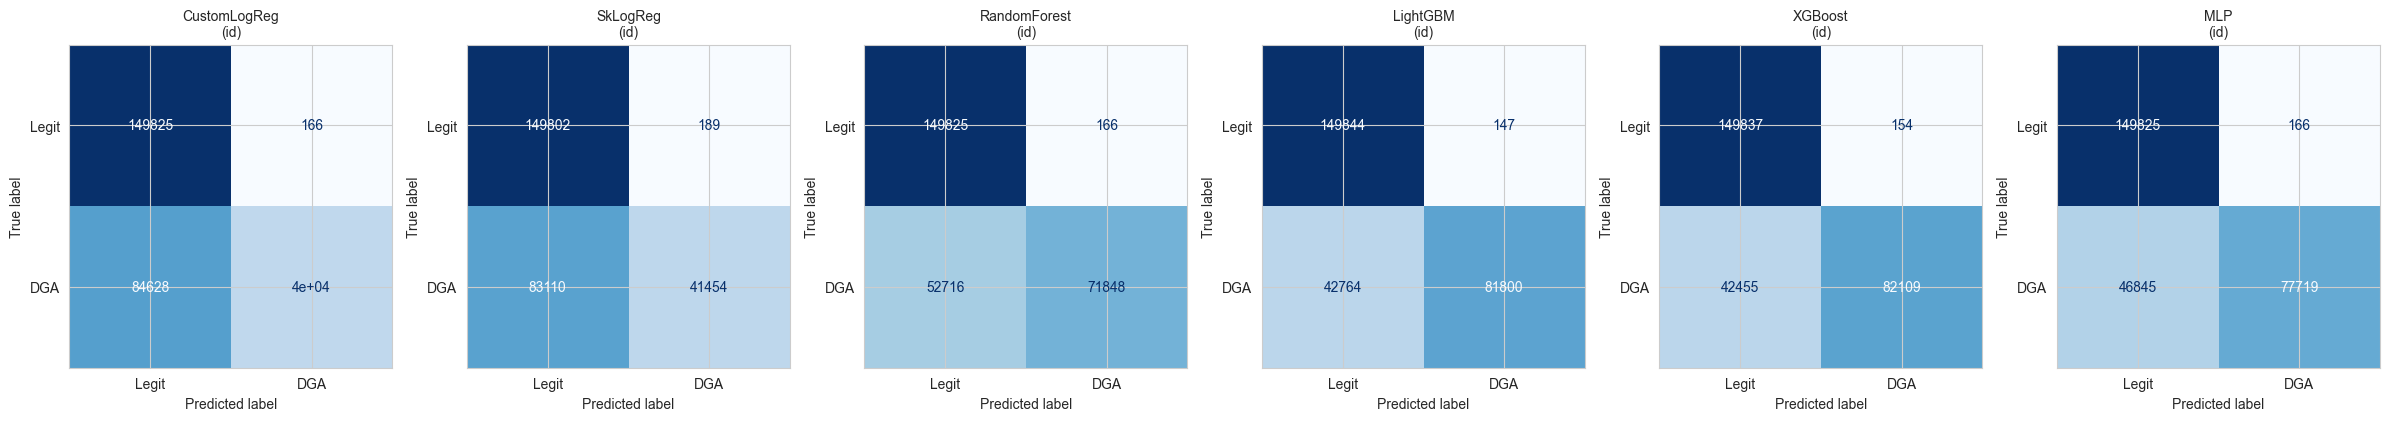

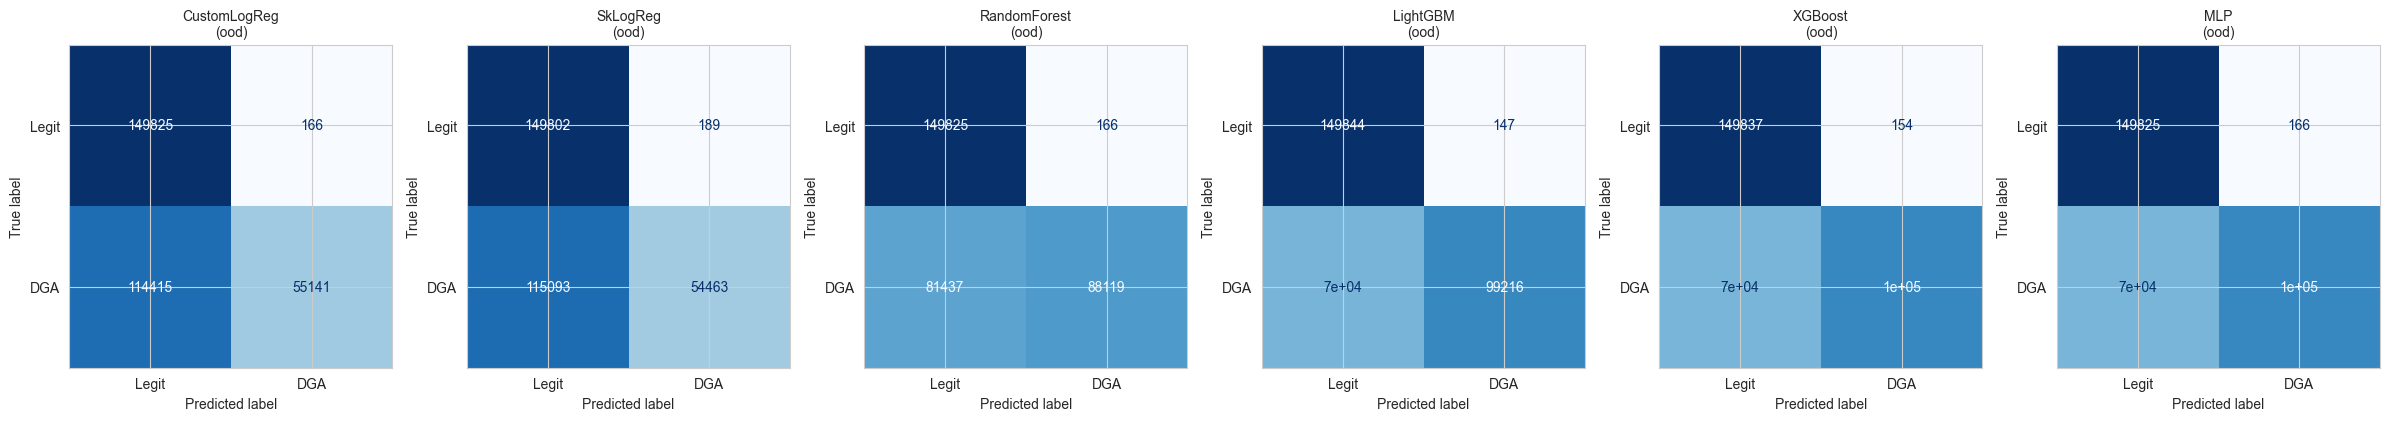

In [57]:
for split in ("id", "ood"):
    y_true = y_test_id if split == "id" else y_test_ood
    n = len(trained_models)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, name in zip(axes, trained_models):
        pred = (test_probs[split][name] >= thresholds[name]).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Legit", "DGA"]).plot(
            ax=ax, cmap="Blues", colorbar=False
        )
        ax.set_title(f"{name}\n({split})", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/cm_{split}.png", dpi=140)
    plt.show()

In [58]:
summary = []
for name in trained_models:
    for split in ("id", "ood"):
        y_true = y_test_id if split == "id" else y_test_ood
        m = full_metrics_block(y_true, test_probs[split][name], thresholds[name])
        summary.append(
            {
                "model": name,
                "split": split,
                "f1": m["f1"],
                "pr_auc": m["pr_auc"],
                "tpr": m["tpr"],
                "fpr": m["fpr"],
                "fp_per_million": m["fp_per_million"],
                "tpr@fpr=1e-3": m["tpr@fpr=1e-3"],
                "prec@prev=1e-3": m["prec@prev=0.001"],
                "single_ms": latency[name]["single_ms"],
            }
        )

summary_df = pd.DataFrame(summary).set_index(["model", "split"])
print("=== Summary test_id vs test_ood ===")
print(summary_df.round(5).to_string())

=== Summary test_id vs test_ood ===
                         f1   pr_auc      tpr      fpr  fp_per_million  tpr@fpr=1e-3  prec@prev=1e-3  single_ms
model        split                                                                                             
CustomLogReg id     0.48505  0.92314  0.32061  0.00111      1106.73307       0.30131         0.22479    0.04320
             ood    0.49044  0.93769  0.32521  0.00111      1106.73307       0.29692         0.22729    0.04320
SkLogReg     id     0.49882  0.92598  0.33279  0.00126      1260.07560       0.30404         0.20909    0.80262
             ood    0.48583  0.93688  0.32121  0.00126      1260.07560       0.27981         0.20329    0.80262
RandomForest id     0.73099  0.96236  0.57680  0.00111      1106.73307       0.57103         0.34284   28.89499
             ood    0.68351  0.94423  0.51970  0.00111      1106.73307       0.51272         0.31975   28.89499
LightGBM     id     0.79221  0.98066  0.65669  0.00098       980.058